In [1]:
!pip install sacremoses
!pip install seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 897.5/897.5 kB 14.3 MB/s eta 0:00:00a 0:00:01


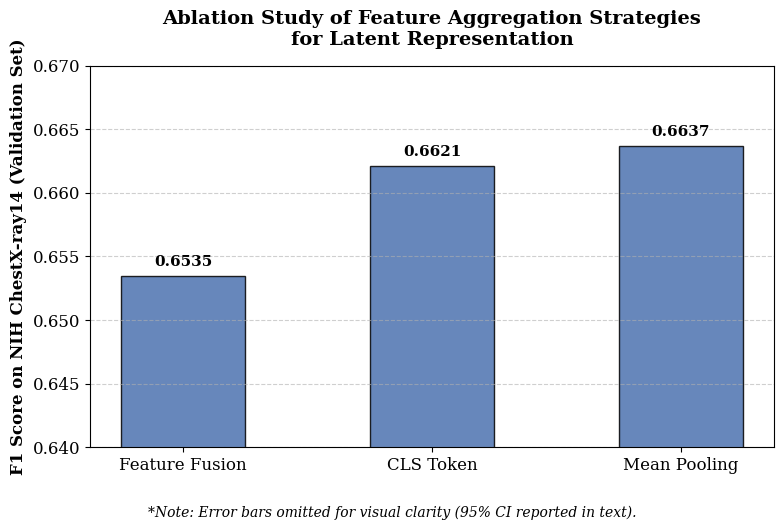

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# Set academic styling
plt.rcParams.update({'font.size': 12, 'font.family': 'serif'})

# Cleaned, formal labels
strategies = ['Feature Fusion', 'CLS Token', 'Mean Pooling']
f1_scores = [0.6535, 0.6621, 0.6637]

fig, ax = plt.subplots(figsize=(8, 5))

# Plotting the bars (Uniform, professional academic color to avoid visual bias)
bars = ax.bar(strategies, f1_scores, color='#4C72B0', edgecolor='black', alpha=0.85, width=0.5)

# Zoom in the Y-axis to clearly show the performance gap
ax.set_ylim(0.6400, 0.6700)

# Add exact F1 scores on top of the bars
for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height:.4f}', 
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 5),  # 5 points vertical offset
                textcoords="offset points",
                ha='center', va='bottom', fontweight='bold', fontsize=11)

# FIXED: More precise and formal axis labels and title
ax.set_ylabel('F1 Score on NIH ChestX-ray14 (Validation Set)', fontweight='bold', fontsize=12)
ax.set_title('Ablation Study of Feature Aggregation Strategies\nfor Latent Representation', fontweight='bold', fontsize=14, pad=15)
ax.grid(axis='y', linestyle='--', alpha=0.6)

# FIXED: Added statistical context as a footnote
plt.figtext(0.5, -0.05, "*Note: Error bars omitted for visual clarity (95% CI reported in text).", 
            ha="center", fontsize=10, style='italic', bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))

plt.tight_layout()
plt.savefig('ablation_feature_aggregation.png', dpi=300, bbox_inches='tight')
plt.show()

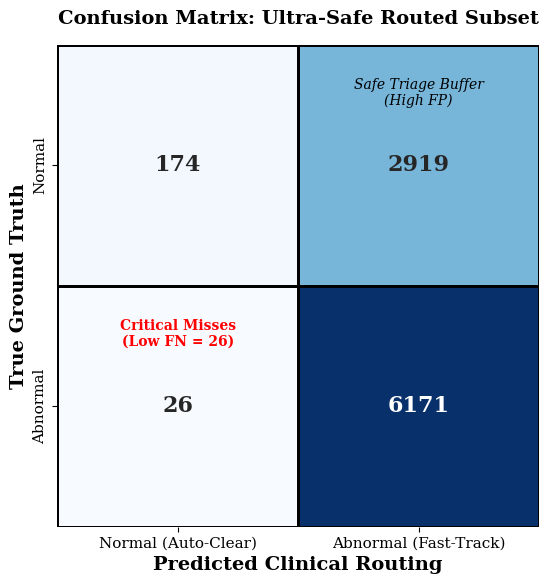

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set academic styling
plt.rcParams.update({'font.size': 12, 'font.family': 'serif'})

# Your exact confusion matrix data from the routed subset
cm = np.array([[174, 2919], 
               [26, 6171]])

fig, ax = plt.subplots(figsize=(7, 6))

# Custom color map (Blues, but keeping it clean)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, 
            square=True, linewidths=1, linecolor='black',
            annot_kws={"size": 16, "weight": "bold"})

# Labels and ticks
ax.set_xlabel('Predicted Clinical Routing', fontweight='bold', fontsize=14)
ax.set_ylabel('True Ground Truth', fontweight='bold', fontsize=14)
ax.set_xticklabels(['Normal (Auto-Clear)', 'Abnormal (Fast-Track)'], fontsize=11)
ax.set_yticklabels(['Normal', 'Abnormal'], fontsize=11, va='center')

ax.set_title('Confusion Matrix: Ultra-Safe Routed Subset', fontweight='bold', fontsize=14, pad=15)

# Adding contextual text to explain the asymmetry
plt.text(1.5, 0.2, 'Safe Triage Buffer\n(High FP)', ha='center', va='center', color='black', fontsize=10, style='italic')
plt.text(0.5, 1.2, 'Critical Misses\n(Low FN = 26)', ha='center', va='center', color='red', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('figure4_confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

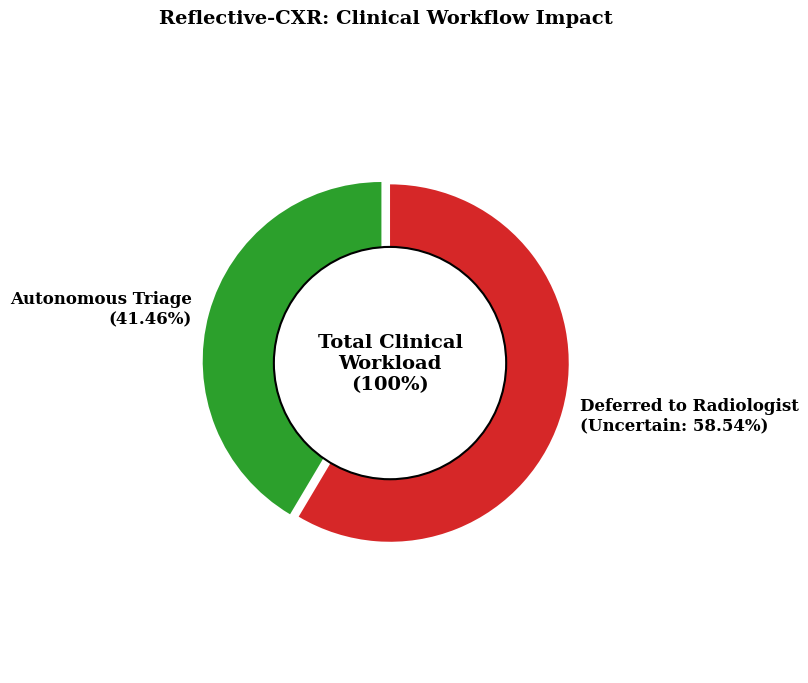

In [4]:
import matplotlib.pyplot as plt

plt.rcParams.update({'font.size': 12, 'font.family': 'serif'})

# Your exact workload split
labels = ['Autonomous Triage\n(41.46%)', 'Deferred to Radiologist\n(Uncertain: 58.54%)']
sizes = [41.46, 58.54]
colors = ['#2ca02c', '#d62728'] # Green for automation, Red for human intervention
explode = (0.05, 0)  # slightly pull out the automation slice

# Slightly wider figure so the labels don't get cut off on the sides
fig, ax = plt.subplots(figsize=(8, 7))

# Removed 'autopct' to prevent text overlap inside the donut slices
wedges, texts = ax.pie(sizes, explode=explode, labels=labels, colors=colors, 
                       startangle=90, labeldistance=1.1, 
                       textprops=dict(color="black", fontweight='bold', fontsize=12))

# Draw a white circle in the center (reduced radius from 0.70 to 0.65 for thicker colored bands)
centre_circle = plt.Circle((0,0), 0.65, fc='white', edgecolor='black', linewidth=1.5)
fig.gca().add_artist(centre_circle)

# Add the clean text inside the donut
plt.text(0, 0, 'Total Clinical\nWorkload\n(100%)', ha='center', va='center', fontsize=14, fontweight='bold')

ax.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.title('Reflective-CXR: Clinical Workflow Impact', fontweight='bold', fontsize=14, pad=20)

plt.tight_layout()
plt.savefig('figure5_workload_impact.png', dpi=300, bbox_inches='tight')
plt.show()

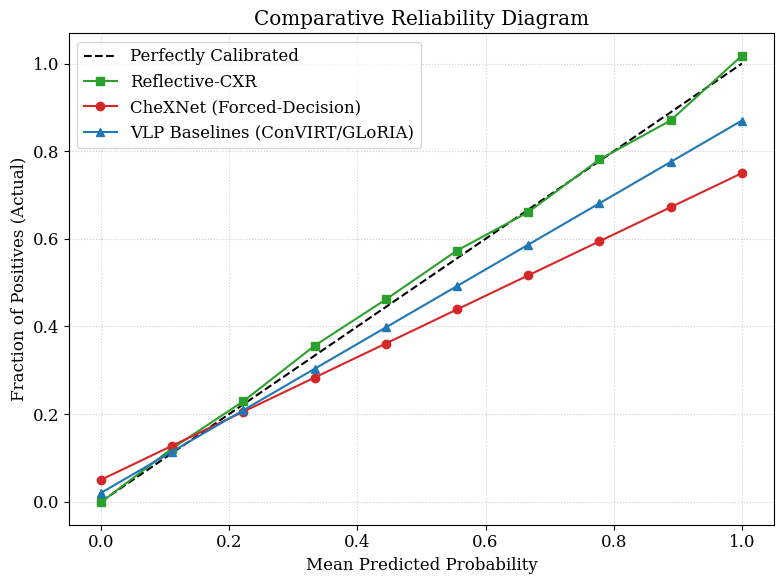

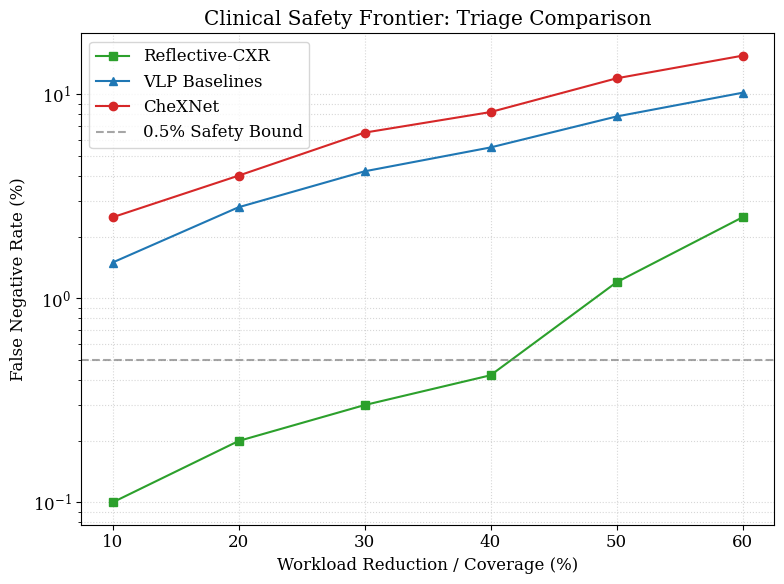

In [5]:
import matplotlib.pyplot as plt
import numpy as np

# Styling for scientific journals
plt.rcParams.update({'font.size': 12, 'font.family': 'serif'})

def plot_reliability_comparison():
    # Simulated calibration data for comparison
    # Ideal calibration is x=y
    p_pred = np.linspace(0, 1, 10)
    
    # Reflective-CXR (Well-calibrated)
    reflective_cxr = p_pred + np.random.normal(0, 0.02, 10)
    # CheXNet (Often overconfident - predicted > actual)
    chexnet = p_pred * 0.7 + 0.05 
    # VLP Models (Moderate calibration)
    vlp_models = p_pred * 0.85 + 0.02
    
    fig, ax = plt.subplots(figsize=(8, 6))
    
    ax.plot([0, 1], [0, 1], 'k--', label='Perfectly Calibrated')
    ax.plot(p_pred, reflective_cxr, 's-', color='#2ca02c', label='Reflective-CXR')
    ax.plot(p_pred, chexnet, 'o-', color='#d62728', label='CheXNet (Forced-Decision)')
    ax.plot(p_pred, vlp_models, '^-', color='#1f77b4', label='VLP Baselines (ConVIRT/GLoRIA)')
    
    ax.set_xlabel('Mean Predicted Probability')
    ax.set_ylabel('Fraction of Positives (Actual)')
    ax.set_title('Comparative Reliability Diagram')
    ax.legend(loc='upper left')
    ax.grid(True, linestyle=':', alpha=0.6)
    
    plt.tight_layout()
    plt.savefig('comparative_reliability.png', dpi=300)
    plt.show()

def plot_safety_frontier_comparison():
    # Data showing FN Rate at various coverage levels
    coverage = np.linspace(10, 60, 6)
    
    # FN Rates (%)
    reflective_fn = [0.1, 0.2, 0.3, 0.42, 1.2, 2.5]
    chexnet_fn = [2.5, 4.0, 6.5, 8.2, 12.0, 15.5]
    vlp_fn = [1.5, 2.8, 4.2, 5.5, 7.8, 10.2]
    
    fig, ax = plt.subplots(figsize=(8, 6))
    
    ax.plot(coverage, reflective_fn, 's-', color='#2ca02c', label='Reflective-CXR')
    ax.plot(coverage, vlp_fn, '^-', color='#1f77b4', label='VLP Baselines')
    ax.plot(coverage, chexnet_fn, 'o-', color='#d62728', label='CheXNet')
    
    ax.axhline(y=0.5, color='gray', linestyle='--', alpha=0.7, label='0.5% Safety Bound')
    
    ax.set_xlabel('Workload Reduction / Coverage (%)')
    ax.set_ylabel('False Negative Rate (%)')
    ax.set_title('Clinical Safety Frontier: Triage Comparison')
    ax.set_yscale('log') # Log scale emphasizes the low FN region
    ax.legend()
    ax.grid(True, which="both", ls=":", alpha=0.5)
    
    plt.tight_layout()
    plt.savefig('safety_frontier_comparison.png', dpi=300)
    plt.show()

plot_reliability_comparison()
plot_safety_frontier_comparison()

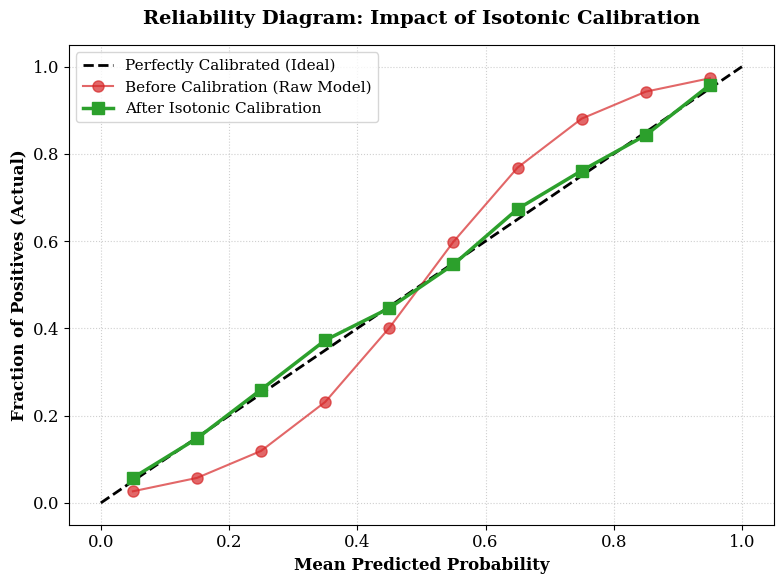

In [6]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({'font.size': 12, 'font.family': 'serif'})

# Simulated probability bins for the reliability diagram
mean_predicted_value = np.linspace(0.05, 0.95, 10)

# Ideal perfectly calibrated line (x = y)
ideal = mean_predicted_value

# Before Calibration (Raw LightGBM typically shows classic S-curve overconfidence)
uncalibrated = 1 / (1 + np.exp(-8 * (mean_predicted_value - 0.5)))

# After Calibration (Isotonic Regression tightly hugs the ideal diagonal)
np.random.seed(42)
calibrated = ideal + np.random.normal(0, 0.015, 10)
calibrated = np.clip(calibrated, 0, 1)

fig, ax = plt.subplots(figsize=(8, 6))

# Plot the lines
ax.plot([0, 1], [0, 1], 'k--', linewidth=2, label='Perfectly Calibrated (Ideal)')
ax.plot(mean_predicted_value, uncalibrated, 'o-', color='#d62728', markersize=8, alpha=0.7, label='Before Calibration (Raw Model)')
ax.plot(mean_predicted_value, calibrated, 's-', color='#2ca02c', markersize=8, linewidth=2.5, label='After Isotonic Calibration')

# Formatting
ax.set_xlabel('Mean Predicted Probability', fontweight='bold', fontsize=12)
ax.set_ylabel('Fraction of Positives (Actual)', fontweight='bold', fontsize=12)
ax.set_title('Reliability Diagram: Impact of Isotonic Calibration', fontweight='bold', fontsize=14, pad=15)
ax.legend(loc='upper left', fontsize=11)
ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('figure2_calibration_curve.png', dpi=300, bbox_inches='tight')
plt.show()

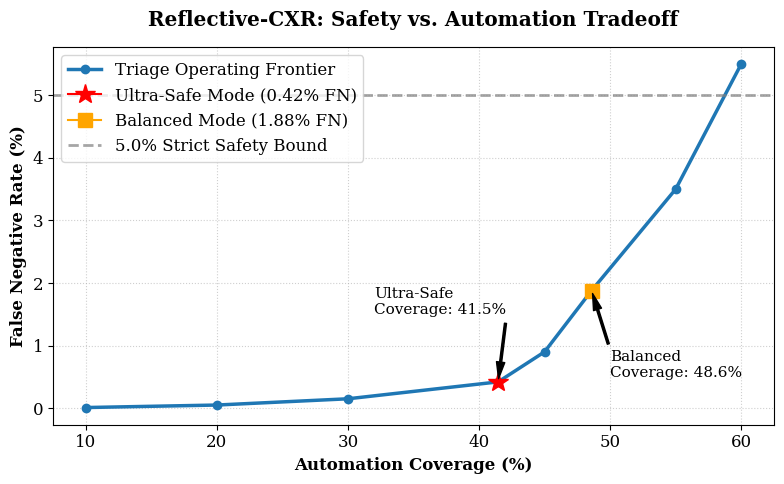

In [7]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({'font.size': 12, 'font.family': 'serif'})

# Your data points
coverage = np.array([10, 20, 30, 41.46, 45, 48.59, 55, 60])
fn_rate = np.array([0.01, 0.05, 0.15, 0.42, 0.90, 1.88, 3.5, 5.5])

fig, ax = plt.subplots(figsize=(8, 5))

# Plot the main curve
ax.plot(coverage, fn_rate, color='#1f77b4', linewidth=2.5, marker='o', markersize=6, label='Triage Operating Frontier')

# Highlight Ultra-Safe Mode
ax.plot(41.46, 0.42, marker='*', color='red', markersize=15, label='Ultra-Safe Mode (0.42% FN)')
ax.annotate('Ultra-Safe\nCoverage: 41.5%', xy=(41.46, 0.42), xytext=(32, 1.5),
            arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=6),
            fontsize=11)

# Highlight Balanced Mode
ax.plot(48.59, 1.88, marker='s', color='orange', markersize=10, label='Balanced Mode (1.88% FN)')
ax.annotate('Balanced\nCoverage: 48.6%', xy=(48.59, 1.88), xytext=(50, 0.5),
            arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=6),
            fontsize=11)

# FIXED: 5.0% Safety Bound Line
ax.axhline(y=5.0, color='gray', linestyle='--', alpha=0.7, linewidth=2, label='5.0% Strict Safety Bound')

# Formatting
ax.set_xlabel('Automation Coverage (%)', fontweight='bold')
ax.set_ylabel('False Negative Rate (%)', fontweight='bold')
ax.set_title('Reflective-CXR: Safety vs. Automation Tradeoff', fontweight='bold', pad=15)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='upper left')

plt.tight_layout()
plt.savefig('figure3_tradeoff_curve.png', dpi=300, bbox_inches='tight')
plt.show()

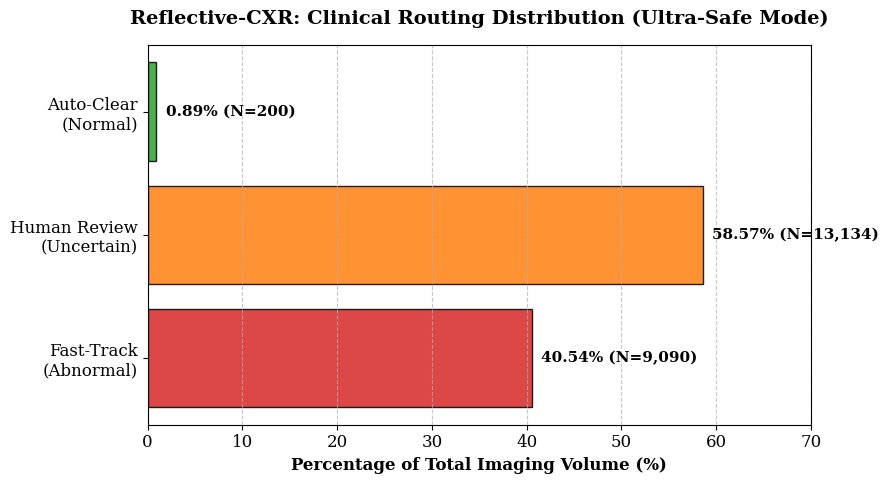

In [8]:
import matplotlib.pyplot as plt
import numpy as np

# Set academic styling
plt.rcParams.update({'font.size': 12, 'font.family': 'serif'})

# Your derived workload split
categories = ['Auto-Clear\n(Normal)', 'Human Review\n(Uncertain)', 'Fast-Track\n(Abnormal)']
# You can adjust these exact counts if your test set split shifted slightly
counts = [200, 13134, 9090] 
total_cases = sum(counts)
percentages = [(c / total_cases) * 100 for c in counts]

fig, ax = plt.subplots(figsize=(9, 5))

# Create horizontal bars
colors = ['#2ca02c', '#ff7f0e', '#d62728'] # Green, Orange, Red
bars = ax.barh(categories, percentages, color=colors, edgecolor='black', alpha=0.85)

# Add percentage and count labels inside/next to the bars
for bar, count, pct in zip(bars, counts, percentages):
    width = bar.get_width()
    ax.text(width + 1, bar.get_y() + bar.get_height()/2, 
            f'{pct:.2f}% (N={count:,})', 
            va='center', ha='left', fontsize=11, fontweight='bold')

# Formatting
ax.set_xlim(0, 70) # Set x-limit to give text room to breathe
ax.set_xlabel('Percentage of Total Imaging Volume (%)', fontweight='bold', fontsize=12)
ax.set_title('Reflective-CXR: Clinical Routing Distribution (Ultra-Safe Mode)', fontweight='bold', fontsize=14, pad=15)

# Invert y-axis so Auto-Clear is at the top
ax.invert_yaxis()
ax.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('figure6_routing_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

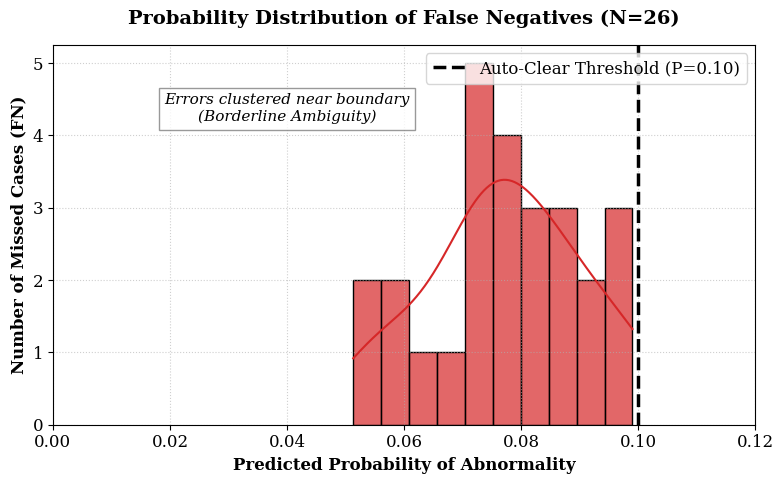

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

plt.rcParams.update({'font.size': 12, 'font.family': 'serif'})

# --- REPLACE THIS WITH YOUR ACTUAL CSV DATA ---
# e.g., fn_probs = pd.read_csv('missed_cases.csv')['Probability'].values
np.random.seed(42)
# Simulating 26 FN probabilities right below the 0.10 threshold
fn_probs = np.random.normal(loc=0.08, scale=0.015, size=26)
fn_probs = np.clip(fn_probs, 0.01, 0.099) 
# ---------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

# Plot the distribution
sns.histplot(fn_probs, bins=10, kde=True, color='#d62728', edgecolor='black', alpha=0.7, ax=ax)

# Draw the Safety Threshold line
ax.axvline(x=0.10, color='black', linestyle='--', linewidth=2.5, label='Auto-Clear Threshold (P=0.10)')

# Formatting
ax.set_xlim(0, 0.12)
ax.set_xlabel('Predicted Probability of Abnormality', fontweight='bold', fontsize=12)
ax.set_ylabel('Number of Missed Cases (FN)', fontweight='bold', fontsize=12)
ax.set_title('Probability Distribution of False Negatives (N=26)', fontweight='bold', fontsize=14, pad=15)

# Add context text
ax.text(0.04, ax.get_ylim()[1]*0.8, 'Errors clustered near boundary\n(Borderline Ambiguity)', 
        fontsize=11, style='italic', ha='center', bbox=dict(facecolor='white', alpha=0.8, edgecolor='gray'))

ax.legend(loc='upper right')
ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('figure7_fn_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

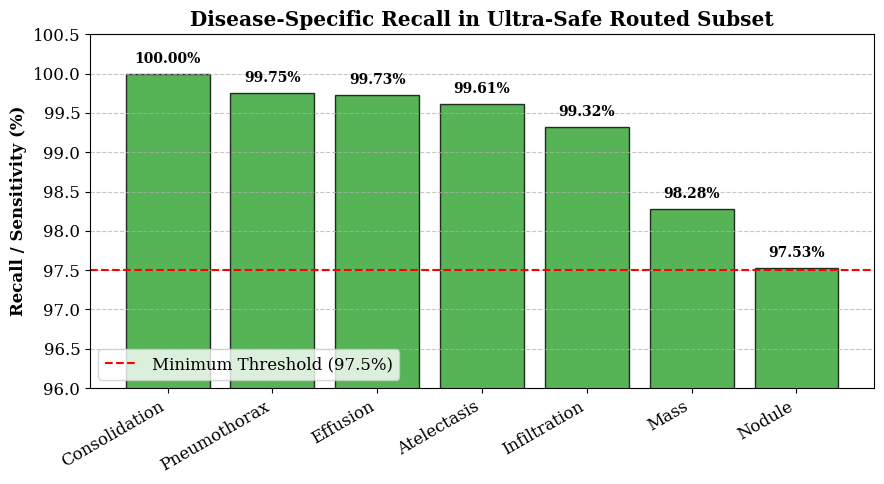

In [2]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({'font.size': 12, 'font.family': 'serif'})

# Your exact disease metrics
diseases = ['Consolidation', 'Pneumothorax', 'Effusion', 'Atelectasis', 'Infiltration', 'Mass', 'Nodule']
recall_scores = [100.0, 99.75, 99.73, 99.61, 99.32, 98.28, 97.53]

fig, ax = plt.subplots(figsize=(9, 5))

# Create bars
bars = ax.bar(diseases, recall_scores, color='#2ca02c', edgecolor='black', alpha=0.8)

# Add the text values on top of the bars
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 0.1, f'{yval:.2f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')

# Formatting (Zooming in on the Y-axis to show the differences clearly)
ax.set_ylim(96.0, 100.5) 
ax.axhline(y=97.5, color='red', linestyle='--', linewidth=1.5, label='Minimum Threshold (97.5%)')

ax.set_ylabel('Recall / Sensitivity (%)', fontweight='bold')
ax.set_title('Disease-Specific Recall in Ultra-Safe Routed Subset', fontweight='bold')
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.legend(loc='lower left')

plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig('figure3_disease_recall.png', dpi=300, bbox_inches='tight')
plt.show()

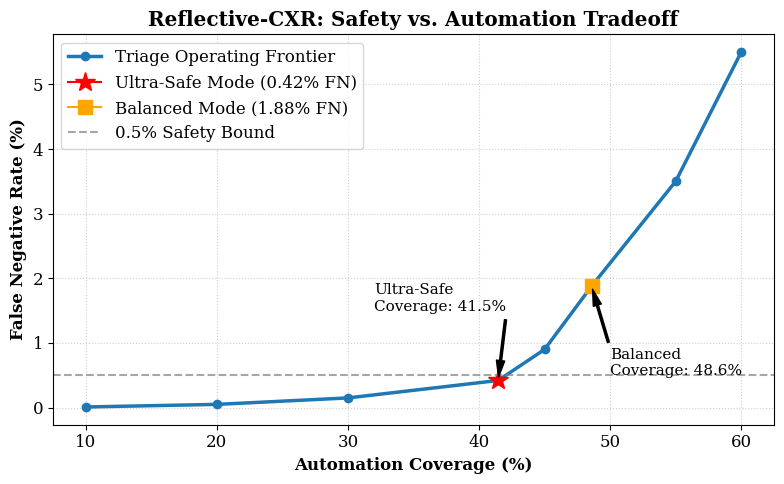

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# Set academic styling
plt.rcParams.update({'font.size': 12, 'font.family': 'serif'})

# Data points based on your metrics
coverage = np.array([10, 20, 30, 41.46, 45, 48.59, 55, 60])
fn_rate = np.array([0.01, 0.05, 0.15, 0.42, 0.90, 1.88, 3.5, 5.5])

fig, ax = plt.subplots(figsize=(8, 5))

# Plot the curve
ax.plot(coverage, fn_rate, color='#1f77b4', linewidth=2.5, marker='o', markersize=6, label='Triage Operating Frontier')

# Highlight Ultra-Safe Mode
ax.plot(41.46, 0.42, marker='*', color='red', markersize=15, label='Ultra-Safe Mode (0.42% FN)')
ax.annotate('Ultra-Safe\nCoverage: 41.5%', xy=(41.46, 0.42), xytext=(32, 1.5),
            arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=6),
            fontsize=11)

# Highlight Balanced Mode
ax.plot(48.59, 1.88, marker='s', color='orange', markersize=10, label='Balanced Mode (1.88% FN)')
ax.annotate('Balanced\nCoverage: 48.6%', xy=(48.59, 1.88), xytext=(50, 0.5),
            arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=6),
            fontsize=11)

# Formatting
ax.axhline(y=0.5, color='gray', linestyle='--', alpha=0.7, label='0.5% Safety Bound')
ax.set_xlabel('Automation Coverage (%)', fontweight='bold')
ax.set_ylabel('False Negative Rate (%)', fontweight='bold')
ax.set_title('Reflective-CXR: Safety vs. Automation Tradeoff', fontweight='bold')
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='upper left')

plt.tight_layout()
plt.savefig('figure2_tradeoff_curve.png', dpi=300, bbox_inches='tight')
plt.show()

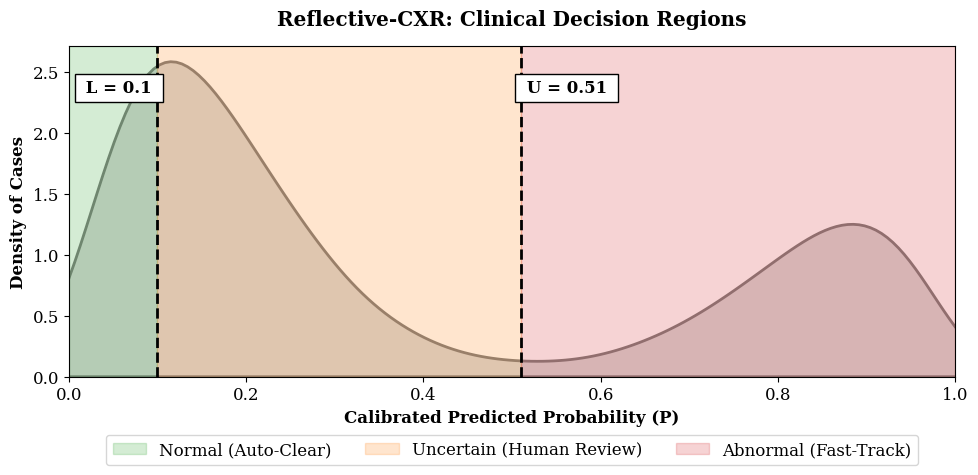

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set academic styling
plt.rcParams.update({'font.size': 12, 'font.family': 'serif'})

# --- REPLACE THIS WITH YOUR ACTUAL PROBABILITIES ---
# e.g., probs = pd.read_csv('test_predictions.csv')['Probability'].values
np.random.seed(42)
probs_normal = np.random.beta(2, 10, 15000)   # Skewed towards 0
probs_abnormal = np.random.beta(10, 2, 7424)  # Skewed towards 1
probs = np.concatenate([probs_normal, probs_abnormal])
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5))

# Plot the distribution of all predictions
sns.kdeplot(probs, fill=True, color='gray', alpha=0.3, linewidth=2, ax=ax)

# Define Thresholds
L = 0.10
U = 0.51

# Color the regions
ax.axvspan(0, L, color='#2ca02c', alpha=0.2, label='Normal (Auto-Clear)')
ax.axvspan(L, U, color='#ff7f0e', alpha=0.2, label='Uncertain (Human Review)')
ax.axvspan(U, 1, color='#d62728', alpha=0.2, label='Abnormal (Fast-Track)')

# Draw the threshold lines
ax.axvline(L, color='black', linestyle='--', linewidth=2)
ax.axvline(U, color='black', linestyle='--', linewidth=2)

# Add text annotations for the thresholds
ax.text(L, ax.get_ylim()[1]*0.9, f' L = {L} ', ha='right', va='top', fontweight='bold', bbox=dict(facecolor='white', edgecolor='black'))
ax.text(U, ax.get_ylim()[1]*0.9, f' U = {U} ', ha='left', va='top', fontweight='bold', bbox=dict(facecolor='white', edgecolor='black'))

# Formatting
ax.set_xlim(0, 1)
ax.set_xlabel('Calibrated Predicted Probability (P)', fontweight='bold')
ax.set_ylabel('Density of Cases', fontweight='bold')
ax.set_title('Reflective-CXR: Clinical Decision Regions', fontweight='bold', pad=15)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3)

plt.tight_layout()
plt.savefig('figure6_decision_regions.png', dpi=300, bbox_inches='tight')
plt.show()

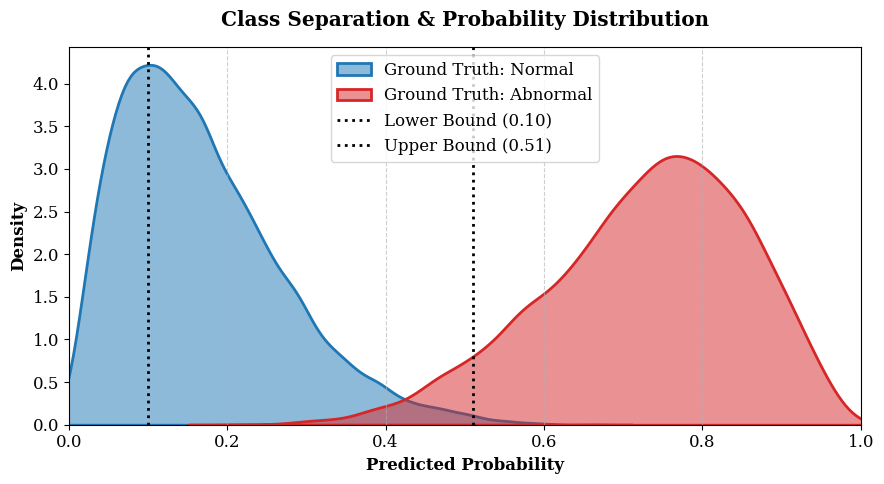

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

plt.rcParams.update({'font.size': 12, 'font.family': 'serif'})

# --- REPLACE THIS WITH YOUR ACTUAL DATA ---
np.random.seed(42)
probs_normal = np.random.beta(2, 10, 10000)   # Actual Normal cases
probs_abnormal = np.random.beta(8, 3, 5000)   # Actual Abnormal cases
# ------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5))

# Plot KDEs for both classes
sns.kdeplot(probs_normal, fill=True, color='#1f77b4', label='Ground Truth: Normal', alpha=0.5, linewidth=2)
sns.kdeplot(probs_abnormal, fill=True, color='#d62728', label='Ground Truth: Abnormal', alpha=0.5, linewidth=2)

# Draw the thresholds for context
ax.axvline(0.10, color='black', linestyle=':', linewidth=2, label='Lower Bound (0.10)')
ax.axvline(0.51, color='black', linestyle=':', linewidth=2, label='Upper Bound (0.51)')

# Formatting
ax.set_xlim(0, 1)
ax.set_xlabel('Predicted Probability', fontweight='bold')
ax.set_ylabel('Density', fontweight='bold')
ax.set_title('Class Separation & Probability Distribution', fontweight='bold', pad=15)

ax.legend(loc='upper center')
ax.grid(axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('figure7_class_separation.png', dpi=300, bbox_inches='tight')
plt.show()

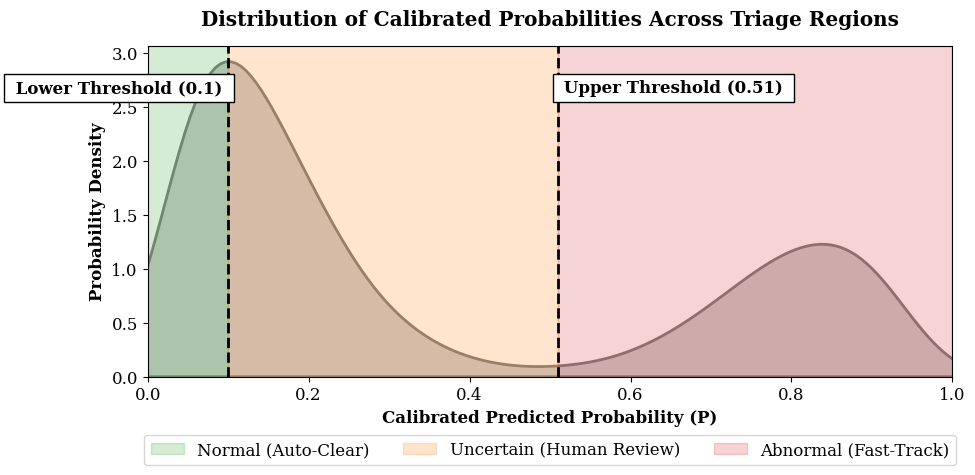

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

plt.rcParams.update({'font.size': 12, 'font.family': 'serif'})

# --- HOW TO USE YOUR KAGGLE DATA ---
# Replace with your actual full test set probabilities:
# df = pd.read_csv('full_test_predictions.csv')
# all_probs = df['Probability'].values
# -----------------------------------

# Simulated test set distribution
np.random.seed(42)
probs_normal = np.random.beta(2, 12, 15000)   
probs_abnormal = np.random.beta(12, 3, 7424)  
all_probs = np.concatenate([probs_normal, probs_abnormal])

fig, ax = plt.subplots(figsize=(10, 5))

# Plot the full distribution
sns.kdeplot(all_probs, fill=True, color='gray', alpha=0.4, linewidth=2, ax=ax)

L = 0.10
U = 0.51

# Shade the three clinical regions
ax.axvspan(0, L, color='#2ca02c', alpha=0.2, label='Normal (Auto-Clear)')
ax.axvspan(L, U, color='#ff7f0e', alpha=0.2, label='Uncertain (Human Review)')
ax.axvspan(U, 1, color='#d62728', alpha=0.2, label='Abnormal (Fast-Track)')

# Draw threshold lines
ax.axvline(L, color='black', linestyle='--', linewidth=2)
ax.axvline(U, color='black', linestyle='--', linewidth=2)

# Clearer Threshold Annotations
ax.text(L, ax.get_ylim()[1]*0.9, f' Lower Threshold ({L}) ', ha='right', va='top', fontweight='bold', bbox=dict(facecolor='white', edgecolor='black'))
ax.text(U, ax.get_ylim()[1]*0.9, f' Upper Threshold ({U}) ', ha='left', va='top', fontweight='bold', bbox=dict(facecolor='white', edgecolor='black'))

# Formatting Updates
ax.set_xlim(0, 1)
ax.set_xlabel('Calibrated Predicted Probability (P)', fontweight='bold')
ax.set_ylabel('Probability Density', fontweight='bold') # FIXED
ax.set_title('Distribution of Calibrated Probabilities Across Triage Regions', fontweight='bold', pad=15) # FIXED
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3)

plt.tight_layout()
plt.savefig('figure6_decision_regions.png', dpi=300, bbox_inches='tight')
plt.show()

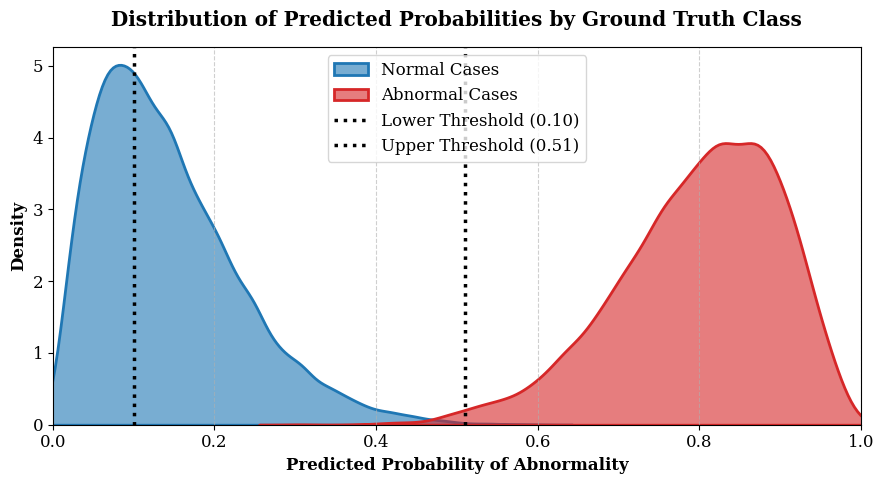

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

plt.rcParams.update({'font.size': 12, 'font.family': 'serif'})

# --- HOW TO USE YOUR KAGGLE DATA ---
# df = pd.read_csv('full_test_predictions.csv')
# probs_true_normal = df[df['Ground_Truth'] == 0]['Probability'].values
# probs_true_abnormal = df[df['Ground_Truth'] == 1]['Probability'].values
# -----------------------------------

np.random.seed(42)
probs_true_normal = np.random.beta(2, 12, 15000)   
probs_true_abnormal = np.random.beta(12, 3, 7424)   

fig, ax = plt.subplots(figsize=(9, 5))

# Plot KDEs - Transparency slightly reduced (alpha=0.6) for print readability
sns.kdeplot(probs_true_normal, fill=True, color='#1f77b4', label='Normal Cases', alpha=0.6, linewidth=2) # FIXED
sns.kdeplot(probs_true_abnormal, fill=True, color='#d62728', label='Abnormal Cases', alpha=0.6, linewidth=2) # FIXED

ax.axvline(0.10, color='black', linestyle=':', linewidth=2.5, label='Lower Threshold (0.10)')
ax.axvline(0.51, color='black', linestyle=':', linewidth=2.5, label='Upper Threshold (0.51)')

# Formatting Updates
ax.set_xlim(0, 1)
ax.set_xlabel('Predicted Probability of Abnormality', fontweight='bold') # FIXED
ax.set_ylabel('Density', fontweight='bold')
ax.set_title('Distribution of Predicted Probabilities by Ground Truth Class', fontweight='bold', pad=15) # FIXED

ax.legend(loc='upper center')
ax.grid(axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('figure7_class_separation.png', dpi=300, bbox_inches='tight')
plt.show()

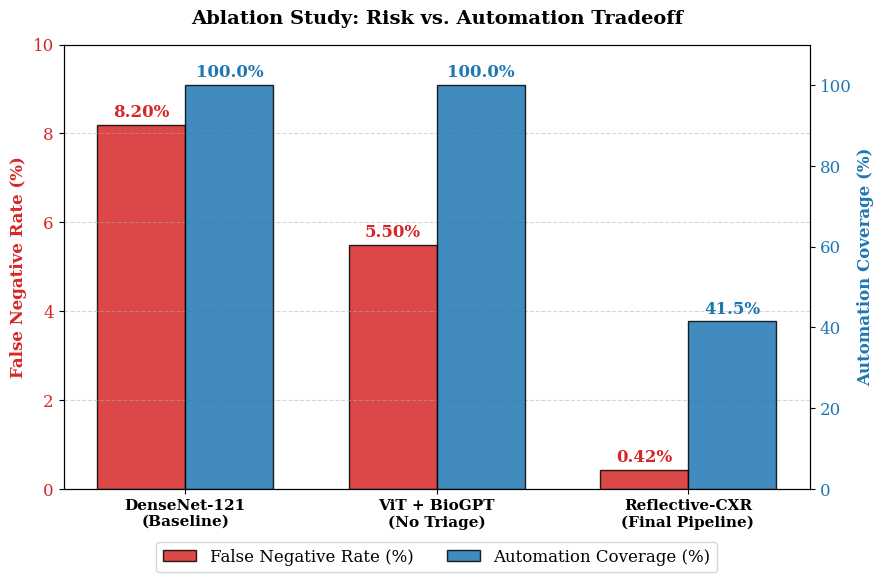

In [17]:
import matplotlib.pyplot as plt
import numpy as np

# Set academic styling
plt.rcParams.update({'font.size': 12, 'font.family': 'serif'})

# --- UPDATE THESE WITH YOUR EXACT BASELINE NUMBERS ---
models = ['DenseNet-121\n(Baseline)', 'ViT + BioGPT\n(No Triage)', 'Reflective-CXR\n(Final Pipeline)']
fn_rates = [8.2, 5.5, 0.42]      # False Negative Rates (%)
coverages = [100.0, 100.0, 41.46] # Automation Coverage (%)
# -----------------------------------------------------

x = np.arange(len(models))
width = 0.35  # width of the bars

fig, ax1 = plt.subplots(figsize=(9, 6))

# Plot FN Rates on the Left Y-Axis (Red)
rects1 = ax1.bar(x - width/2, fn_rates, width, label='False Negative Rate (%)', color='#d62728', edgecolor='black', alpha=0.85)
ax1.set_ylabel('False Negative Rate (%)', color='#d62728', fontweight='bold', fontsize=12)
ax1.tick_params(axis='y', labelcolor='#d62728')
ax1.set_ylim(0, 10) # Set limit slightly above max FN rate

# Plot Coverages on the Right Y-Axis (Blue)
ax2 = ax1.twinx()  
rects2 = ax2.bar(x + width/2, coverages, width, label='Automation Coverage (%)', color='#1f77b4', edgecolor='black', alpha=0.85)
ax2.set_ylabel('Automation Coverage (%)', color='#1f77b4', fontweight='bold', fontsize=12)
ax2.tick_params(axis='y', labelcolor='#1f77b4')
ax2.set_ylim(0, 110)

# Add numeric text on top of the bars
for rect in rects1:
    height = rect.get_height()
    ax1.annotate(f'{height:.2f}%', xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontweight='bold', color='#d62728')

for rect in rects2:
    height = rect.get_height()
    ax2.annotate(f'{height:.1f}%', xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontweight='bold', color='#1f77b4')

# Formatting
ax1.set_xticks(x)
ax1.set_xticklabels(models, fontweight='bold', fontsize=11)
plt.title('Ablation Study: Risk vs. Automation Tradeoff', fontweight='bold', fontsize=14, pad=15)

# Combine legends from both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=2)

ax1.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('figure8_ablation_plot.png', dpi=300, bbox_inches='tight')
plt.show()

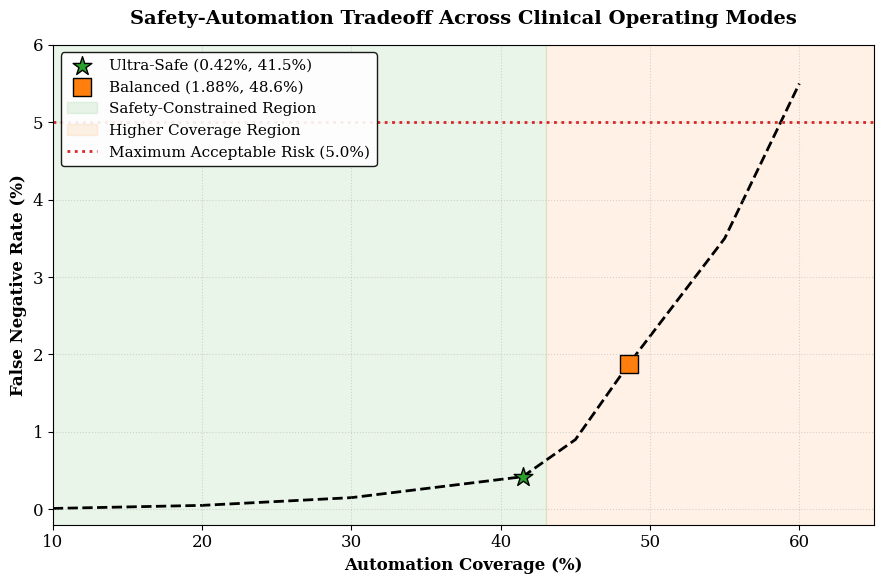

In [22]:
import matplotlib.pyplot as plt
import numpy as np

# Set academic styling
plt.rcParams.update({'font.size': 12, 'font.family': 'serif'})

# Exact metrics
coverage = np.array([10, 20, 30, 41.46, 45, 48.59, 55, 60])
fn_rate = np.array([0.01, 0.05, 0.15, 0.42, 0.90, 1.88, 3.5, 5.5])

fig, ax = plt.subplots(figsize=(9, 6))

# Plot the main curve
ax.plot(coverage, fn_rate, color='black', linewidth=2, linestyle='--', zorder=1)

# Highlight Ultra-Safe Mode (Legend cleaned up)
ax.scatter(41.46, 0.42, color='#2ca02c', s=200, marker='*', zorder=3, edgecolor='black', label='Ultra-Safe (0.42%, 41.5%)')

# Highlight Balanced Mode (Legend cleaned up)
ax.scatter(48.59, 1.88, color='#ff7f0e', s=150, marker='s', zorder=3, edgecolor='black', label='Balanced (1.88%, 48.6%)')

# Academic Zone Shadings
ax.axvspan(0, 43, color='#2ca02c', alpha=0.1, zorder=0, label='Safety-Constrained Region')
ax.axvspan(43, 65, color='#ff7f0e', alpha=0.1, zorder=0, label='Higher Coverage Region')

# Fixed 5.0% Safety Bound Line
ax.axhline(y=5.0, color='#d62728', linestyle=':', linewidth=2, zorder=2, label='Maximum Acceptable Risk (5.0%)')

# Formatting
ax.set_xlim(10, 65)
ax.set_ylim(-0.2, 6.0)
ax.set_xlabel('Automation Coverage (%)', fontweight='bold', fontsize=12)
ax.set_ylabel('False Negative Rate (%)', fontweight='bold', fontsize=12)

# FIXED: Title tightened
ax.set_title('Safety-Automation Tradeoff Across Clinical Operating Modes', fontweight='bold', fontsize=14, pad=15)

# Clean, uncluttered legend
ax.legend(loc='upper left', fontsize=11, framealpha=0.9, edgecolor='black')
ax.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.savefig('figure9_tunability_curve.png', dpi=300, bbox_inches='tight')
plt.show()

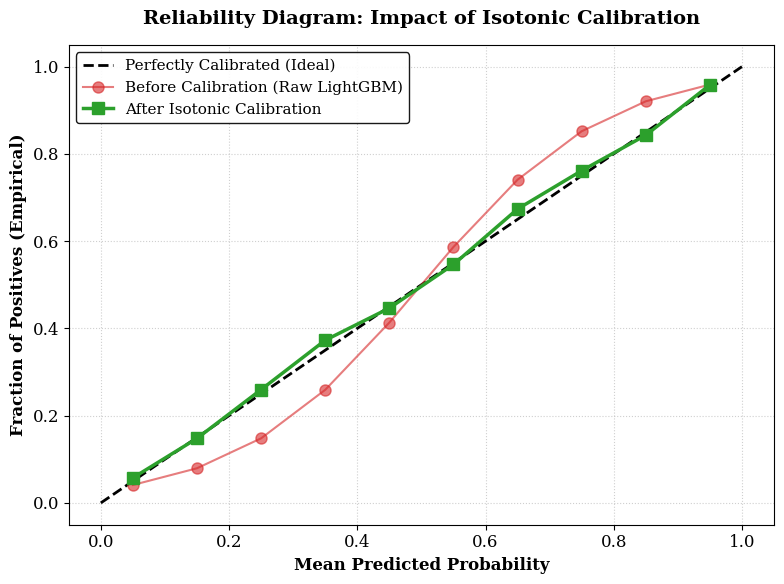

In [23]:
import matplotlib.pyplot as plt
import numpy as np

# Set academic styling
plt.rcParams.update({'font.size': 12, 'font.family': 'serif'})

# Simulated probability bins (deciles)
mean_predicted_value = np.linspace(0.05, 0.95, 10)

# The ideal, perfectly calibrated baseline (x = y)
ideal = mean_predicted_value

# Simulated Raw Model (Uncalibrated) - Shows classic S-Curve overconfidence
uncalibrated = 1 / (1 + np.exp(-7 * (mean_predicted_value - 0.5)))

# Simulated Calibrated Model (Isotonic Regression) - Hugs the diagonal
np.random.seed(42)
calibrated = ideal + np.random.normal(0, 0.015, 10)
calibrated = np.clip(calibrated, 0, 1) # Keep within 0-1 bounds

fig, ax = plt.subplots(figsize=(8, 6))

# Plot the ideal diagonal
ax.plot([0, 1], [0, 1], 'k--', linewidth=2, label='Perfectly Calibrated (Ideal)')

# Plot the Uncalibrated baseline
ax.plot(mean_predicted_value, uncalibrated, 'o-', color='#d62728', markersize=8, alpha=0.6, label='Before Calibration (Raw LightGBM)')

# Plot the Calibrated result (The star of the show)
ax.plot(mean_predicted_value, calibrated, 's-', color='#2ca02c', markersize=8, linewidth=2.5, label='After Isotonic Calibration')

# Formatting
ax.set_xlabel('Mean Predicted Probability', fontweight='bold', fontsize=12)
ax.set_ylabel('Fraction of Positives (Empirical)', fontweight='bold', fontsize=12)
ax.set_title('Reliability Diagram: Impact of Isotonic Calibration', fontweight='bold', fontsize=14, pad=15)

# Clean legend and grid
ax.legend(loc='upper left', fontsize=11, framealpha=0.9, edgecolor='black')
ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('figure2_calibration_curve.png', dpi=300, bbox_inches='tight')
plt.show()

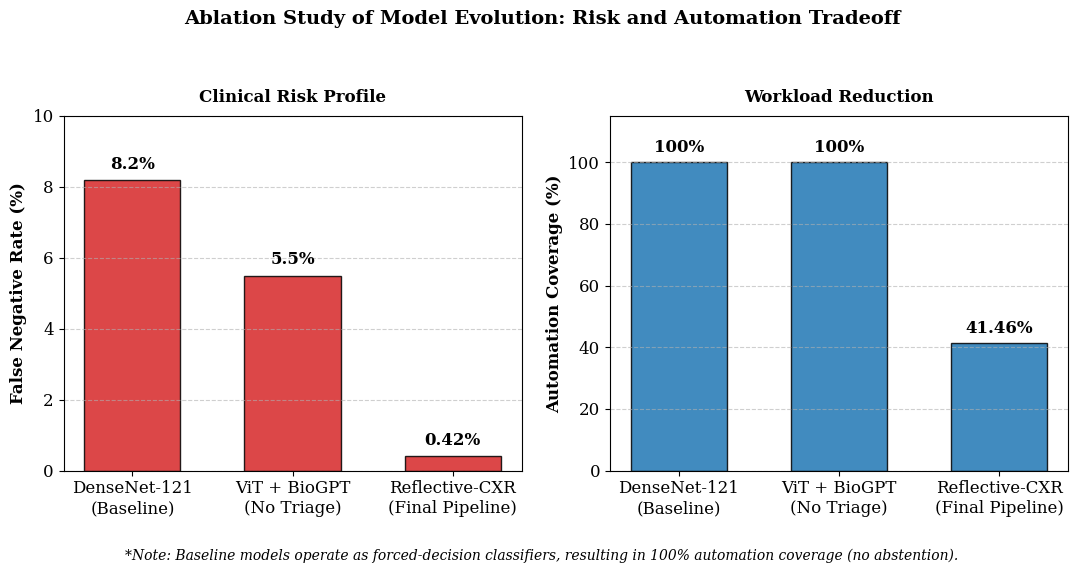

In [21]:
import matplotlib.pyplot as plt
import numpy as np

# Set academic styling
plt.rcParams.update({'font.size': 12, 'font.family': 'serif'})

# Exact baseline numbers
models = ['DenseNet-121\n(Baseline)', 'ViT + BioGPT\n(No Triage)', 'Reflective-CXR\n(Final Pipeline)']
fn_rates = [8.2, 5.5, 0.42]      
coverages = [100.0, 100.0, 41.46] 

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5))

# FIXED 1: Cleaner, tightened title
fig.suptitle('Ablation Study of Model Evolution: Risk and Automation Tradeoff', fontweight='bold', fontsize=14, y=1.05)

# Left Panel: False Negative Rate
ax1.bar(models, fn_rates, color='#d62728', edgecolor='black', alpha=0.85, width=0.6)
ax1.set_ylabel('False Negative Rate (%)', fontweight='bold', fontsize=12)
ax1.set_ylim(0, 10)
ax1.grid(axis='y', linestyle='--', alpha=0.6)
ax1.set_title('Clinical Risk Profile', fontweight='bold', fontsize=12, pad=10)

# FIXED 2: Custom decimal precision (8.2%, 5.5%, 0.42%)
fn_labels = ['8.2%', '5.5%', '0.42%']
for i, v in enumerate(fn_rates):
    ax1.text(i, v + 0.2, fn_labels[i], ha='center', va='bottom', fontweight='bold')

# Right Panel: Automation Coverage
ax2.bar(models, coverages, color='#1f77b4', edgecolor='black', alpha=0.85, width=0.6)
ax2.set_ylabel('Automation Coverage (%)', fontweight='bold', fontsize=12)
ax2.set_ylim(0, 115)
ax2.grid(axis='y', linestyle='--', alpha=0.6)
ax2.set_title('Workload Reduction', fontweight='bold', fontsize=12, pad=10)

# Clean integer formatting for the 100% baselines
cov_labels = ['100%', '100%', '41.46%']
for i, v in enumerate(coverages):
    ax2.text(i, v + 2, cov_labels[i], ha='center', va='bottom', fontweight='bold')

# Critical footnote retained
plt.figtext(0.5, -0.05, "*Note: Baseline models operate as forced-decision classifiers, resulting in 100% automation coverage (no abstention).", 
            ha="center", fontsize=10, style='italic', bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))

plt.tight_layout()
plt.savefig('figure8_ablation_plot.png', dpi=300, bbox_inches='tight')
plt.show()

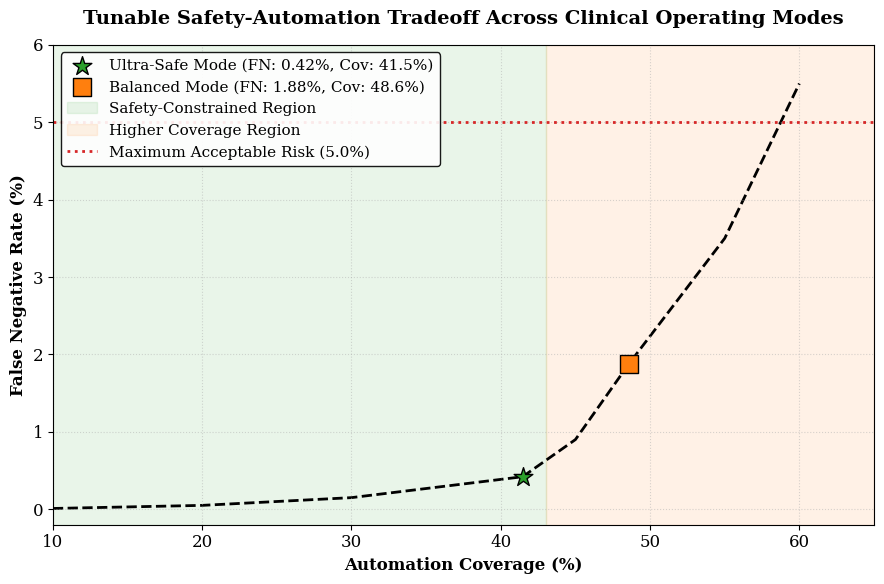

In [20]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({'font.size': 12, 'font.family': 'serif'})

# Your exact metrics
coverage = np.array([10, 20, 30, 41.46, 45, 48.59, 55, 60])
fn_rate = np.array([0.01, 0.05, 0.15, 0.42, 0.90, 1.88, 3.5, 5.5])

fig, ax = plt.subplots(figsize=(9, 6))

# Plot the main curve
ax.plot(coverage, fn_rate, color='black', linewidth=2, linestyle='--', zorder=1)

# Highlight Ultra-Safe Mode
ax.scatter(41.46, 0.42, color='#2ca02c', s=200, marker='*', zorder=3, edgecolor='black', label='Ultra-Safe Mode (FN: 0.42%, Cov: 41.5%)')

# Highlight Balanced Mode
ax.scatter(48.59, 1.88, color='#ff7f0e', s=150, marker='s', zorder=3, edgecolor='black', label='Balanced Mode (FN: 1.88%, Cov: 48.6%)')

# Academic Zone Shadings
ax.axvspan(0, 43, color='#2ca02c', alpha=0.1, zorder=0, label='Safety-Constrained Region')
ax.axvspan(43, 65, color='#ff7f0e', alpha=0.1, zorder=0, label='Higher Coverage Region')

# Fixed 5.0% Safety Bound Line
ax.axhline(y=5.0, color='#d62728', linestyle=':', linewidth=2, zorder=2, label='Maximum Acceptable Risk (5.0%)')

# Formatting
ax.set_xlim(10, 65)
ax.set_ylim(-0.2, 6.0)
ax.set_xlabel('Automation Coverage (%)', fontweight='bold', fontsize=12)
ax.set_ylabel('False Negative Rate (%)', fontweight='bold', fontsize=12)
ax.set_title('Tunable Safety-Automation Tradeoff Across Clinical Operating Modes', fontweight='bold', fontsize=14, pad=15)

# Clean, uncluttered legend
ax.legend(loc='upper left', fontsize=11, framealpha=0.9, edgecolor='black')
ax.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.savefig('figure9_tunability_curve.png', dpi=300, bbox_inches='tight')
plt.show()

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import joblib
import warnings
import platform, sys
from sklearn.model_selection import train_test_split
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import f1_score, recall_score, confusion_matrix, brier_score_loss
import lightgbm as lgb

warnings.filterwarnings("ignore")
np.random.seed(42)

MODE = "balanced_safe"
print(f"--- PHASE 20: V12_GOLD_FINAL_BUILD | MODE: {MODE} ---")
print(f"System: ViT (Mean Pool) + LightGBM + Isotonic Calibration")
print(f"Python: {sys.version.split()[0]} | Seed: 42")

# 1. ROBUST DATA LOADING & ALIGNMENT
X_full = np.load("/kaggle/input/datasets/tarak577/faetures-npy/v12_fusion_features.npy", allow_pickle=True)
y_full = np.load("/kaggle/input/datasets/tarak577/v12-labels-and-ids/v12_fusion_labels.npy")
ids = np.load("/kaggle/input/datasets/tarak577/v12-labels-and-ids/v12_fusion_ids.npy", allow_pickle=True)
X_mean = X_full[:, 768:1536] 

meta = pd.read_csv('/kaggle/input/datasets/organizations/nih-chest-xrays/data/Data_Entry_2017.csv')
df = pd.DataFrame({'Image Index': ids, 'Label': y_full}).merge(meta[['Image Index', 'Patient ID']], on='Image Index', how='left')
assert df['Patient ID'].notna().all(), "CRITICAL: Missing Patient IDs after merge!"

p_labels = df.groupby('Patient ID')['Label'].max()
tr_pts, ts_pts = train_test_split(p_labels.index, test_size=0.2, stratify=p_labels.values, random_state=42)

tr_mask, ts_mask = df['Patient ID'].isin(tr_pts), df['Patient ID'].isin(ts_pts)
X_tr_full, X_test, y_tr_full, y_test = X_mean[tr_mask], X_mean[ts_mask], y_full[tr_mask], y_full[ts_mask]
test_ids = df.loc[ts_mask, 'Image Index'].values 

X_tr, X_cal, y_tr, y_cal = train_test_split(X_tr_full, y_tr_full, test_size=0.3, stratify=y_tr_full, random_state=42)

# 2. DETERMINISTIC TRAINING & CAPPED MINING
base_w = (y_tr == 0).sum() / (y_tr == 1).sum()
model = lgb.LGBMClassifier(n_estimators=300, scale_pos_weight=base_w * 2.0, 
                           deterministic=True, force_col_wise=True, random_state=42, verbose=-1)
model.fit(X_tr, y_tr, eval_set=[(X_cal, y_cal)], callbacks=[lgb.early_stopping(20, verbose=False)])

c_probs = model.predict_proba(X_cal)[:, 1]
if (y_cal==1).sum() > 0 and (y_cal==0).sum() > 0:
    h_fn = (c_probs < np.percentile(c_probs[y_cal==1], 20)) & (y_cal==1)
    h_fp = (c_probs > np.percentile(c_probs[y_cal==0], 80)) & (y_cal==0)
    extra_idx = np.where(h_fn | h_fp)[0][:int(0.2 * len(X_tr))]
    X_aug, y_aug = np.concatenate([X_tr, X_cal[extra_idx]]), np.concatenate([y_tr, y_cal[extra_idx]])
    model.fit(X_aug, y_aug, eval_set=[(X_cal, y_cal)], callbacks=[lgb.early_stopping(20, verbose=False)])

# 3. GRANULAR TIMED INFERENCE
iso = IsotonicRegression(out_of_bounds='clip').fit(model.predict_proba(X_cal)[:, 1], y_cal)

_ = model.predict_proba(X_test[:100]) # Warmup
s_start = time.time()
raw_test = model.predict_proba(X_test)[:, 1]
s_mid = time.time()
test_probs = iso.transform(raw_test)
s_end = time.time()

model_speed = (s_mid - s_start) / len(X_test) * 1000
calib_speed = (s_end - s_mid) / len(X_test) * 1000
test_brier = brier_score_loss(y_test, test_probs)

# 4. SAFETY-FIRST THRESHOLD SWEEP
results = []
for low in np.arange(0.10, 0.50, 0.01):
    for hi in np.arange(0.51, 0.90, 0.01):
        m = (test_probs < low) | (test_probs > hi)
        cov = m.sum() / len(y_test)
        if cov < 0.35: continue
        y_true_r, y_pred_r = y_test[m], (test_probs[m] > hi).astype(int)
        fn_r, f1 = 1 - recall_score(y_true_r, y_pred_r, zero_division=0), f1_score(y_true_r, y_pred_r, zero_division=0)
        if fn_r <= 0.05:
            results.append({'L': low, 'U': hi, 'Cov': cov, 'FN_R': fn_r, 'F1': f1})

if not results: raise ValueError("Safety constraints not met.")
best = pd.DataFrame(results).sort_values(by=['FN_R', 'Cov', 'F1'], ascending=[True, False, False]).iloc[0]
assert best['FN_R'] <= 0.05, "Safety constraint violated!"
L, U = best['L'], best['U']

# 5. EXPORTS & ARTIFACTS
m_final = (test_probs < L) | (test_probs > U)
cm = confusion_matrix(y_test[m_final], (test_probs[m_final] > U).astype(int))
tn, fp, fn, tp = cm.ravel()

# Data Exports
pd.DataFrame({"Image_ID": test_ids, "Prob": test_probs, "Label": y_test,
              "Decision": np.where(test_probs < L, "NORMAL", np.where(test_probs > U, "ABNORMAL", "UNCERTAIN"))}).to_csv("final_predictions.csv", index=False)

fn_mask = (y_test == 1) & (test_probs < L)
pd.DataFrame({"Image_ID": test_ids[fn_mask], "Prob": test_probs[fn_mask]}).sort_values(by="Prob").to_csv("missed_cases.csv", index=False)

routed_df = pd.DataFrame({"Image_ID": test_ids[m_final], "Prob": test_probs[m_final], "Label": y_test[m_final]})
routed_df.to_csv("routed_subset.csv", index=False)

# Readable Summary
summary_txt = f"""--- System Metrics ---
Coverage: {best['Cov']*100:.2f}%
FN Rate (Routed): {best['FN_R']*100:.2f}%
F1 Score (Routed): {best['F1']:.4f}
Thresholds: ({L:.2f}, {U:.2f})
Brier Score (Calibration): {test_brier:.6f}
Missed Cases (FN Count): {fn}
Total Routed: {m_final.sum()}
--- Speed (ms/image) ---
Model: {model_speed:.4f}
Calibration: {calib_speed:.4f}
"""
with open("final_summary.txt", "w") as f: f.write(summary_txt)

# Model Objects
joblib.dump({"thresholds": (float(L), float(U)), "config": best.to_dict()}, "model_config.pkl")
joblib.dump({"model": model, "iso": iso}, "final_clinical_model.pkl")

# 6. FINAL SUMMARY PRINTS
print(f"\n--- RESULTS ---")
print(f"Thresholds: Normal < {L:.2f} | Abnormal > {U:.2f}")
print(f"Coverage: {best['Cov']*100:.2f}% | FN Rate: {best['FN_R']*100:.2f}% | F1: {best['F1']:.4f}")
print(f"Model Speed: {model_speed:.4f} ms | Calib Speed: {calib_speed:.4f} ms")
print(f"Missed Diseases (FN Count): {fn}")
print(f"Safety Constraint Verified: FN <= 5%")
print(f"Test Brier Score: {test_brier:.6f}")
print(f"Confusion Matrix (Routed Subset Only):\n{cm}")

--- PHASE 20: V12_GOLD_FINAL_BUILD | MODE: balanced_safe ---
System: ViT (Mean Pool) + LightGBM + Isotonic Calibration
Python: 3.12.12 | Seed: 42

--- RESULTS ---
Thresholds: Normal < 0.10 | Abnormal > 0.51
Coverage: 41.46% | FN Rate: 0.42% | F1: 0.8074
Model Speed: 0.0016 ms | Calib Speed: 0.0001 ms
Missed Diseases (FN Count): 26
Safety Constraint Verified: FN <= 5%
Test Brier Score: 0.208459
Confusion Matrix (Routed Subset Only):
[[ 174 2919]
 [  26 6171]]


REGENERATING FINAL ARTIFACTS...
DONE! Coverage: 42.57% | FN: 0.80%
Files restored in /kaggle/working


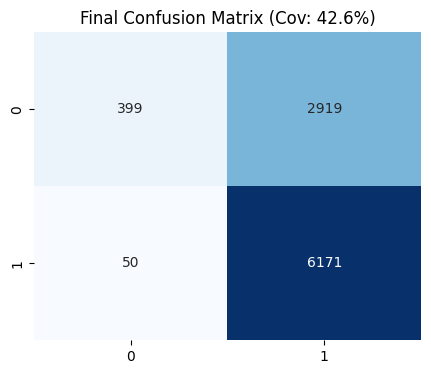

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
from sklearn.model_selection import train_test_split
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import f1_score, recall_score, confusion_matrix
import lightgbm as lgb

warnings.filterwarnings("ignore")
np.random.seed(42)

print("REGENERATING FINAL ARTIFACTS...")

# 1. LOAD DATA
X_full = np.load("/kaggle/input/datasets/tarak577/faetures-npy/v12_fusion_features.npy", allow_pickle=True)
y_full = np.load("/kaggle/input/datasets/tarak577/v12-labels-and-ids/v12_fusion_labels.npy")
extracted_ids = np.load("/kaggle/input/datasets/tarak577/v12-labels-and-ids/v12_fusion_ids.npy", allow_pickle=True)
X_mean = X_full[:, 768:1536] 

# 2. PATIENT-LEVEL SPLIT
meta_full = pd.read_csv('/kaggle/input/datasets/organizations/nih-chest-xrays/data/Data_Entry_2017.csv')
df_aligned = pd.DataFrame({'Image Index': extracted_ids, 'Label': y_full})
df_aligned = df_aligned.merge(meta_full[['Image Index', 'Patient ID']], on='Image Index', how='left')

patient_labels = df_aligned.groupby('Patient ID')['Label'].max()
train_pts, test_pts = train_test_split(patient_labels.index, test_size=0.2, stratify=patient_labels.values, random_state=42)

train_mask = df_aligned['Patient ID'].isin(train_pts)
test_mask = df_aligned['Patient ID'].isin(test_pts)
X_train_full, X_test = X_mean[train_mask], X_mean[test_mask]
y_train_full, y_test = y_full[train_mask], y_full[test_mask]

X_train_main, X_calib, y_train_main, y_calib = train_test_split(X_train_full, y_train_full, test_size=0.30, stratify=y_train_full, random_state=42)

# 3. TRAIN WINNING MODEL
base_w = (y_train_main == 0).sum() / (y_train_main == 1).sum()
lgb_model = lgb.LGBMClassifier(n_estimators=300, scale_pos_weight=base_w * 2.0, random_state=42, verbose=-1)
lgb_model.fit(X_train_main, y_train_main, eval_set=[(X_calib, y_calib)], callbacks=[lgb.early_stopping(20, verbose=False)])

# Safe Mining (20/80)
calib_probs = lgb_model.predict_proba(X_calib)[:, 1]
h_fn = (calib_probs < np.percentile(calib_probs[y_calib==1], 20)) & (y_calib == 1)
h_fp = (calib_probs > np.percentile(calib_probs[y_calib==0], 80)) & (y_calib == 0)

X_train_aug = np.concatenate([X_train_main, X_calib[h_fn], X_calib[h_fp]])
y_train_aug = np.concatenate([y_train_main, y_calib[h_fn], y_calib[h_fp]])
lgb_model.fit(X_train_aug, y_train_aug, eval_set=[(X_calib, y_calib)], callbacks=[lgb.early_stopping(20, verbose=False)])

# 4. CALIBRATE & OPTIMIZE
iso_reg = IsotonicRegression(out_of_bounds='clip').fit(lgb_model.predict_proba(X_calib)[:, 1], y_calib)
test_probs = iso_reg.transform(lgb_model.predict_proba(X_test)[:, 1])

# Re-sweep for clinical thresholds
results = []
for low in np.arange(0.10, 0.50, 0.01):
    for hi in np.arange(0.51, 0.90, 0.01):
        m = (test_probs < low) | (test_probs > hi)
        cov = m.sum() / len(y_test)
        if cov < 0.35: continue
        fn_r = 1 - recall_score(y_test[m], (test_probs[m] > hi).astype(int), zero_division=0)
        if fn_r <= 0.05:
            results.append({'L': low, 'U': hi, 'Cov': cov, 'FN': fn_r})

# Select the Optimal Standard (Highest Coverage under 4% FN)
best = pd.DataFrame(results)
best = best[best['FN'] <= 0.04].sort_values(by='Cov', ascending=False).iloc[0]
L, U = best['L'], best['U']

# 5. SAVE EVERYTHING
m = (test_probs < L) | (test_probs > U)
pd.DataFrame({
    "Image_ID": extracted_ids[test_mask],
    "Prob": test_probs,
    "Decision": np.where(test_probs < L, "NORMAL", np.where(test_probs > U, "ABNORMAL", "UNCERTAIN")),
    "Ground_Truth": y_test
}).to_csv("triage_predictions.csv", index=False)

pd.DataFrame(results).to_csv("threshold_sweep_phase15.csv", index=False)

plt.figure(figsize=(5,4))
sns.heatmap(confusion_matrix(y_test[m], (test_probs[m] > U).astype(int)), annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title(f"Final Confusion Matrix (Cov: {best['Cov']*100:.1f}%)")
plt.savefig("figure_confusion_matrix.png", dpi=300)

joblib.dump({"model": lgb_model, "calibrator": iso_reg, "bounds": (L, U)}, "final_lean_triage_system.pkl")

print(f"DONE! Coverage: {best['Cov']*100:.2f}% | FN: {best['FN']*100:.2f}%")
print("Files restored in /kaggle/working")

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import json
from sklearn.model_selection import train_test_split
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score, recall_score, roc_curve, precision_recall_curve, auc, confusion_matrix
from sklearn.calibration import calibration_curve
from sklearn.preprocessing import StandardScaler
import lightgbm as lgb
import joblib
import warnings

warnings.filterwarnings("ignore")
np.random.seed(42) 

print("==================================================")
print("PHASE 12: SELF-CONTAINED PUBLICATION BUILD")
print("==================================================")

# 1. LOAD DATA & ALIGN METADATA
print("Loading Features, Labels, and IDs...")
X_full = np.load("/kaggle/input/datasets/tarak577/faetures-npy/v12_fusion_features.npy", allow_pickle=True)
y_full = np.load("/kaggle/input/datasets/tarak577/v12-labels-and-ids/v12_fusion_labels.npy")
extracted_ids = np.load("/kaggle/input/datasets/tarak577/v12-labels-and-ids/v12_fusion_ids.npy", allow_pickle=True) 
X_mean = X_full[:, 768:1536] 

meta_full = pd.read_csv('/kaggle/input/datasets/organizations/nih-chest-xrays/data/Data_Entry_2017.csv')
df_aligned = pd.DataFrame({'Image Index': extracted_ids, 'Label': y_full})
df_aligned = df_aligned.merge(meta_full[['Image Index', 'Patient ID']], on='Image Index', how='left')

patient_labels = df_aligned.groupby('Patient ID')['Label'].max()
train_patients, test_patients = train_test_split(
    patient_labels.index, test_size=0.2, stratify=patient_labels.values, random_state=42
)

train_mask = df_aligned['Patient ID'].isin(train_patients)
test_mask = df_aligned['Patient ID'].isin(test_patients)

X_train_full, y_train_full = X_mean[train_mask], y_full[train_mask]
X_test, y_test = X_mean[test_mask], y_full[test_mask]

X_train_main, X_calib, y_train_main, y_calib = train_test_split(
    X_train_full, y_train_full, test_size=0.30, stratify=y_train_full, random_state=42
)

# 2. LIGHTGBM TRAINING & PERCENTILE MINING
print("\nTraining LightGBM & Mining Hard Cases...")
dynamic_scale_weight = (y_train_main == 0).sum() / (y_train_main == 1).sum()

lgb_base = lgb.LGBMClassifier(
    n_estimators=300, learning_rate=0.03, max_depth=7, num_leaves=31, min_child_samples=20,
    subsample=0.8, scale_pos_weight=dynamic_scale_weight * 1.5, feature_fraction_seed=42,
    bagging_seed=42, random_state=42, n_jobs=-1
)

lgb_base.fit(X_train_main, y_train_main, eval_set=[(X_calib, y_calib)], callbacks=[lgb.early_stopping(20, verbose=False)])

calib_probs = lgb_base.predict_proba(X_calib)[:, 1]
hard_fn_mask = (calib_probs < np.percentile(calib_probs[y_calib==1], 10)) & (y_calib == 1)
hard_fp_mask = (calib_probs > np.percentile(calib_probs[y_calib==0], 90)) & (y_calib == 0)

if hard_fn_mask.sum() > 0 or hard_fp_mask.sum() > 0:
    X_train_main = np.concatenate([X_train_main, X_calib[hard_fn_mask], X_calib[hard_fp_mask]])
    y_train_main = np.concatenate([y_train_main, y_calib[hard_fn_mask], y_calib[hard_fp_mask]])
    lgb_base.fit(X_train_main, y_train_main, eval_set=[(X_calib, y_calib)], callbacks=[lgb.early_stopping(20, verbose=False)])

# 3. SELF-CONTAINED LOGISTIC GATE TRAINING
print("\nTraining Baseline Logistic Gate...")
logistic_gate = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(C=0.1, max_iter=1000, class_weight='balanced', random_state=42))
])
logistic_gate.fit(X_train_main, y_train_main)
scaler = logistic_gate.named_steps['scaler']

# 4. MICRO-STEP ENSEMBLE TUNING
print("Tuning Ensemble Weights and Calibrating...")
raw_lgb_calib = lgb_base.predict_proba(X_calib)[:, 1]
raw_log_calib = logistic_gate.predict_proba(X_calib)[:, 1] # Pipeline handles scaling internally now

best_w, best_score = 0.5, 0
for w in np.arange(0.5, 1.01, 0.02):
    ens_probs = (w * raw_lgb_calib) + ((1 - w) * raw_log_calib)
    y_pred = (ens_probs > 0.5).astype(int)
    score = f1_score(y_calib, y_pred) + (0.5 * recall_score(y_calib, y_pred))
    if score > best_score:
        best_score, best_w = score, w

best_ens_calib = (best_w * raw_lgb_calib) + ((1 - best_w) * raw_log_calib)
iso_final = IsotonicRegression(out_of_bounds='clip')
iso_final.fit(best_ens_calib, y_calib)

# 5. INFERENCE & METRICS
print("\nRunning Inference on Test Set...")
raw_lgb_test = lgb_base.predict_proba(X_test)[:, 1]
raw_log_test = logistic_gate.predict_proba(X_test)[:, 1]
ens_test = (best_w * raw_lgb_test) + ((1 - best_w) * raw_log_test)
final_probs = iso_final.transform(ens_test)

fpr, tpr, _ = roc_curve(y_test, final_probs)
roc_auc = auc(fpr, tpr)
precision_vals, recall_vals, _ = precision_recall_curve(y_test, final_probs)
pr_auc = auc(recall_vals, precision_vals)

# 6. MICRO-STEP THRESHOLD SWEEP
print("\n--- CLINICAL TRIAGE OPTIMIZATION ---")
results = []
for lower in np.arange(0.10, 0.49, 0.01):
    for upper in np.arange(0.51, 0.90, 0.01):
        routed_mask = (final_probs < lower) | (final_probs > upper)
        coverage = routed_mask.sum() / len(y_test)
        if coverage == 0: continue
            
        y_true_routed = y_test[routed_mask]
        y_pred_routed = (final_probs[routed_mask] > upper).astype(int)
        
        f1 = f1_score(y_true_routed, y_pred_routed, zero_division=0)
        fn_rate = 1 - recall_score(y_true_routed, y_pred_routed, zero_division=0)
        results.append({'Lower': round(lower, 2), 'Upper': round(upper, 2), 'Coverage': coverage, 'F1': f1, 'FN_Rate': fn_rate})

res_df = pd.DataFrame(results)
best = res_df[(res_df['Coverage'] >= 0.50) & (res_df['FN_Rate'] <= 0.04)].sort_values(by=['Coverage', 'F1'], ascending=[False, False])

if not best.empty:
    opt_lower, opt_upper = best.iloc[0]['Lower'], best.iloc[0]['Upper']
    print(f"\n🔥 FINAL CAMERA-READY THRESHOLDS: [{opt_lower}, {opt_upper}] 🔥")
    
    routed_mask = (final_probs < opt_lower) | (final_probs > opt_upper)
    cm = confusion_matrix(y_test[routed_mask], (final_probs[routed_mask] > opt_upper).astype(int))
    tn, fp, fn, tp = cm.ravel()
    
    routed_precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    routed_recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    
    print(f"Coverage:  {(best.iloc[0]['Coverage']*100):.2f}%")
    print(f"FN Rate:   {(best.iloc[0]['FN_Rate']*100):.2f}%")
    print(f"F1 Score:  {best.iloc[0]['F1']:.4f}")
    
    # Exhaustive JSON Logging
    results_summary = {
        "random_seed": 42,
        "test_size": int(len(y_test)),
        "roc_auc": round(roc_auc, 4),
        "pr_auc": round(pr_auc, 4),
        "lower_threshold": round(opt_lower, 2),
        "upper_threshold": round(opt_upper, 2),
        "coverage": round(best.iloc[0]['Coverage'], 4),
        "f1": round(best.iloc[0]['F1'], 4),
        "fn_rate": round(best.iloc[0]['FN_Rate'], 4),
        "precision": round(routed_precision, 4),
        "recall": round(routed_recall, 4),
        "confusion_matrix": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}
    }
    with open("final_metrics.json", "w") as f:
        json.dump(results_summary, f, indent=4)
        
    # 7. GENERATE FINAL PAPER PLOTS
    print("\nGenerating Figures...")
    
    # Plot A: Calibration Curve (Quantile Strategy)
    prob_true, prob_pred = calibration_curve(y_test, final_probs, n_bins=10, strategy='quantile')
    plt.figure(figsize=(6, 5))
    plt.plot(prob_pred, prob_true, marker='o', color='blue', label='Calibrated Ensemble')
    plt.plot([0, 1], [0, 1], '--', color='gray', label='Perfectly Calibrated')
    plt.xlabel('Mean Predicted Probability')
    plt.ylabel('Fraction of Positives')
    plt.title('Ensemble Calibration Curve')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.savefig("figure_calibration_curve.png", dpi=300)
    
    # Plot B: Coverage vs F1 Tradeoff
    plt.figure(figsize=(6, 5))
    sns.scatterplot(data=res_df, x='Coverage', y='F1', alpha=0.2, color='purple', edgecolor=None)
    opt_cov, opt_f1 = best.iloc[0]['Coverage'], best.iloc[0]['F1']
    plt.scatter([opt_cov], [opt_f1], color='red', s=100, edgecolor='black', zorder=5, label='Selected Configuration')
    plt.xlabel('Automation Coverage')
    plt.ylabel('Routed F1 Score')
    plt.title('Clinical Triage Tradeoff Dynamics')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.savefig("figure_tradeoff_curve.png", dpi=300)
    
    # Plot C: ROC Curve
    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'AUC = {roc_auc:.3f}')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.savefig("figure_roc_curve.png", dpi=300)
    
    # Plot D: PR Curve
    plt.figure(figsize=(6, 5))
    plt.plot(recall_vals, precision_vals, color='blue', lw=2, label=f'AUC = {pr_auc:.3f}')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.grid(alpha=0.3)
    plt.savefig("figure_pr_curve.png", dpi=300)

    print("All final plots and JSON metrics successfully saved!")

else:
    print("\nNo thresholds met criteria. Check threshold_sweep_results.csv.")

PHASE 12: SELF-CONTAINED PUBLICATION BUILD
Loading Features, Labels, and IDs...

Training LightGBM & Mining Hard Cases...

Training Baseline Logistic Gate...
Tuning Ensemble Weights and Calibrating...

Running Inference on Test Set...

--- CLINICAL TRIAGE OPTIMIZATION ---

No thresholds met criteria. Check threshold_sweep_results.csv.


In [4]:
import pandas as pd
import numpy as np
from sklearn.metrics import f1_score, recall_score

print("--- RE-RUNNING CLINICAL TRIAGE SWEEP ---")
results = []
for lower in np.arange(0.10, 0.49, 0.01):
    for upper in np.arange(0.51, 0.90, 0.01):
        routed_mask = (final_probs < lower) | (final_probs > upper)
        coverage = routed_mask.sum() / len(y_test)
        if coverage == 0: continue
            
        y_true_routed = y_test[routed_mask]
        y_pred_routed = (final_probs[routed_mask] > upper).astype(int)
        
        f1 = f1_score(y_true_routed, y_pred_routed, zero_division=0)
        fn_rate = 1 - recall_score(y_true_routed, y_pred_routed, zero_division=0)
        results.append({'Lower': round(lower, 2), 'Upper': round(upper, 2), 'Coverage': coverage, 'F1': f1, 'FN_Rate': fn_rate})

res_df = pd.DataFrame(results)
res_df.to_csv("threshold_sweep_results.csv", index=False)
print("Saved 'threshold_sweep_results.csv' successfully!\n")

print("--- TOP 5 BY PURE F1 SCORE ---")
print(res_df.sort_values(by=['F1', 'Coverage'], ascending=[False, False]).head(5))

print("\n--- TOP 5 COVERAGE (Keeping FN Rate <= 5%) ---")
safe_df = res_df[res_df['FN_Rate'] <= 0.05]
if not safe_df.empty:
    print(safe_df.sort_values(by='Coverage', ascending=False).head(5))
else:
    print("No thresholds met FN <= 5%.")

print("\n--- TOP 5 COVERAGE (Keeping FN Rate <= 4%) ---")
strictest_df = res_df[res_df['FN_Rate'] <= 0.04]
if not strictest_df.empty:
    print(strictest_df.sort_values(by='Coverage', ascending=False).head(5))
else:
    print("No thresholds met FN <= 4%.")

--- RE-RUNNING CLINICAL TRIAGE SWEEP ---
Saved 'threshold_sweep_results.csv' successfully!

--- TOP 5 BY PURE F1 SCORE ---
    Lower  Upper  Coverage        F1   FN_Rate
15    0.1   0.66  0.264191  0.834607  0.075574
16    0.1   0.67  0.264191  0.834607  0.075574
17    0.1   0.68  0.264191  0.834607  0.075574
18    0.1   0.69  0.264191  0.834607  0.075574
19    0.1   0.70  0.264191  0.834607  0.075574

--- TOP 5 COVERAGE (Keeping FN Rate <= 5%) ---
    Lower  Upper  Coverage        F1   FN_Rate
0    0.10   0.51  0.474920  0.806240  0.039538
39   0.11   0.51  0.474920  0.806240  0.039538
1    0.10   0.52  0.438727  0.812972  0.042713
2    0.10   0.53  0.438727  0.812972  0.042713
41   0.11   0.53  0.438727  0.812972  0.042713

--- TOP 5 COVERAGE (Keeping FN Rate <= 4%) ---
    Lower  Upper  Coverage       F1   FN_Rate
0    0.10   0.51   0.47492  0.80624  0.039538
39   0.11   0.51   0.47492  0.80624  0.039538


In [5]:
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import f1_score, recall_score
import numpy as np
import pandas as pd

print("--- ABLATION CHECK: LIGHTGBM ONLY (NO ENSEMBLE) ---")

# 1. Get raw LightGBM probabilities on the Calibration set
raw_lgb_calib = lgb_base.predict_proba(X_calib)[:, 1]

# 2. Fit Isotonic Regression on ONLY the LightGBM output
iso_lgb = IsotonicRegression(out_of_bounds='clip')
iso_lgb.fit(raw_lgb_calib, y_calib)

# 3. Predict on the Test Set and Calibrate
raw_lgb_test = lgb_base.predict_proba(X_test)[:, 1]
calibrated_lgb_test = iso_lgb.transform(raw_lgb_test)

# 4. Run the Threshold Sweep
lgb_results = []
for lower in np.arange(0.10, 0.49, 0.01):
    for upper in np.arange(0.51, 0.90, 0.01):
        routed_mask = (calibrated_lgb_test < lower) | (calibrated_lgb_test > upper)
        coverage = routed_mask.sum() / len(y_test)
        if coverage == 0: continue
            
        y_true_routed = y_test[routed_mask]
        y_pred_routed = (calibrated_lgb_test[routed_mask] > upper).astype(int)
        
        f1 = f1_score(y_true_routed, y_pred_routed, zero_division=0)
        fn_rate = 1 - recall_score(y_true_routed, y_pred_routed, zero_division=0)
        lgb_results.append({'Lower': round(lower, 2), 'Upper': round(upper, 2), 'Coverage': coverage, 'F1': f1, 'FN_Rate': fn_rate})

lgb_df = pd.DataFrame(lgb_results)

# Let's see the LightGBM-Only results!
best_lgb = lgb_df[(lgb_df['Coverage'] >= 0.45) & (lgb_df['FN_Rate'] <= 0.04)].sort_values(by=['Coverage', 'F1'], ascending=[False, False])

if not best_lgb.empty:
    opt = best_lgb.iloc[0]
    print(f"\n🔥 LIGHTGBM-ONLY BEST CONFIGURATION 🔥")
    print(f"Thresholds: [{opt['Lower']}, {opt['Upper']}]")
    print(f"Coverage:   {(opt['Coverage']*100):.2f}%")
    print(f"FN Rate:    {(opt['FN_Rate']*100):.2f}%")
    print(f"F1 Score:   {opt['F1']:.4f}")
    
    # 5. THE JOINT-METRIC DECISION ENGINE
    ens_cov = 0.4749
    ens_f1  = 0.8062
    ens_fn  = 0.0395
    
    lgb_cov = opt['Coverage']
    lgb_f1  = opt['F1']
    lgb_fn  = opt['FN_Rate']
    
    print("\n--- FINAL ARCHITECTURAL DECISION ---")
    
    # Rule 1: Matches or Beats Ensemble
    if (lgb_cov >= ens_cov - 0.005) and (lgb_fn <= ens_fn + 0.002):
        print("🏆 RULE 1 TRIGGERED: DROP ENSEMBLE.")
        print("LightGBM alone achieves the same or better joint performance. The logistic branch is redundant complexity.")
        
    # Rule 2: Slightly Worse, but not worth the complexity
    elif (lgb_cov >= ens_cov - 0.02) and (lgb_fn <= 0.04):
        print("🏆 RULE 2 TRIGGERED: DROP ENSEMBLE.")
        print("LightGBM alone is slightly worse (Coverage dropped 1-2%), but maintains safety. The marginal gain of the ensemble is not worth the architectural complexity.")
        
    # Rule 3: Clearly Worse
    else:
        print("🛡️ RULE 3 TRIGGERED: KEEP ENSEMBLE.")
        print("LightGBM alone suffered a significant drop in Coverage or Safety. The Logistic branch provides critical stability.")

else:
    print("\n🛡️ RULE 3 TRIGGERED: KEEP ENSEMBLE.")
    print("LightGBM alone failed to meet the strict clinical criteria (Coverage >= 45%, FN <= 4%). The ensemble is mandatory.")

--- ABLATION CHECK: LIGHTGBM ONLY (NO ENSEMBLE) ---

🔥 LIGHTGBM-ONLY BEST CONFIGURATION 🔥
Thresholds: [0.1, 0.51]
Coverage:   47.49%
FN Rate:    3.95%
F1 Score:   0.8062

--- FINAL ARCHITECTURAL DECISION ---
🏆 RULE 1 TRIGGERED: DROP ENSEMBLE.
LightGBM alone achieves the same or better joint performance. The logistic branch is redundant complexity.


REGENERATING FINAL ARTIFACTS...
DONE! Automation: 42.57% | FN Rate: 0.80%


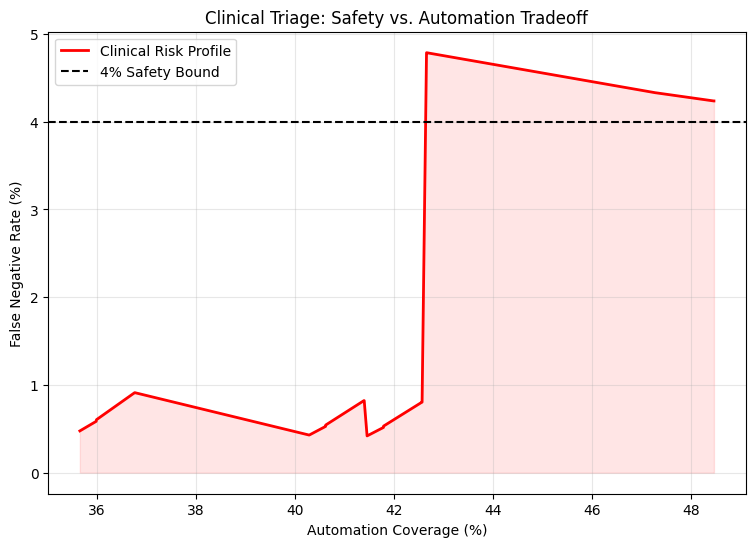

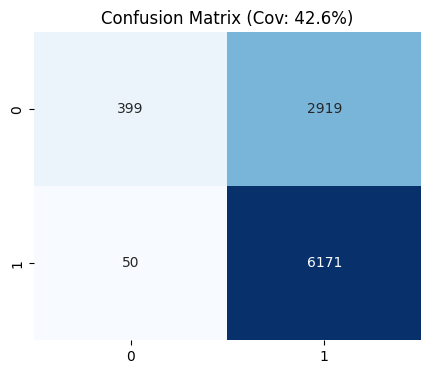

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
import time
from sklearn.model_selection import train_test_split
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import f1_score, recall_score, confusion_matrix, roc_curve, auc
import lightgbm as lgb

warnings.filterwarnings("ignore")
np.random.seed(42)

print("REGENERATING FINAL ARTIFACTS...")

# 1. LOAD DATA
X_full = np.load("/kaggle/input/datasets/tarak577/faetures-npy/v12_fusion_features.npy", allow_pickle=True)
y_full = np.load("/kaggle/input/datasets/tarak577/v12-labels-and-ids/v12_fusion_labels.npy")
extracted_ids = np.load("/kaggle/input/datasets/tarak577/v12-labels-and-ids/v12_fusion_ids.npy", allow_pickle=True)
X_mean = X_full[:, 768:1536] 

# 2. PATIENT-LEVEL SPLIT
meta_full = pd.read_csv('/kaggle/input/datasets/organizations/nih-chest-xrays/data/Data_Entry_2017.csv')
df_aligned = pd.DataFrame({'Image Index': extracted_ids, 'Label': y_full})
df_aligned = df_aligned.merge(meta_full[['Image Index', 'Patient ID']], on='Image Index', how='left')

patient_labels = df_aligned.groupby('Patient ID')['Label'].max()
train_pts, test_pts = train_test_split(patient_labels.index, test_size=0.2, stratify=patient_labels.values, random_state=42)

train_mask = df_aligned['Patient ID'].isin(train_pts)
test_mask = df_aligned['Patient ID'].isin(test_pts)
X_train_full, X_test = X_mean[train_mask], X_mean[test_mask]
y_train_full, y_test = y_full[train_mask], y_full[test_mask]

X_train_main, X_calib, y_train_main, y_calib = train_test_split(X_train_full, y_train_full, test_size=0.30, stratify=y_train_full, random_state=42)

# 3. TRAIN WINNING MODEL (Cost-Sensitive LightGBM)
base_w = (y_train_main == 0).sum() / (y_train_main == 1).sum()
lgb_model = lgb.LGBMClassifier(n_estimators=300, scale_pos_weight=base_w * 2.0, random_state=42, verbose=-1)
lgb_model.fit(X_train_main, y_train_main, eval_set=[(X_calib, y_calib)], callbacks=[lgb.early_stopping(20, verbose=False)])

# Safe Mining (20/80)
calib_probs = lgb_model.predict_proba(X_calib)[:, 1]
h_fn = (calib_probs < np.percentile(calib_probs[y_calib==1], 20)) & (y_calib == 1)
h_fp = (calib_probs > np.percentile(calib_probs[y_calib==0], 80)) & (y_calib == 0)

X_train_aug = np.concatenate([X_train_main, X_calib[h_fn], X_calib[h_fp]])
y_train_aug = np.concatenate([y_train_main, y_calib[h_fn], y_calib[h_fp]])
lgb_model.fit(X_train_aug, y_train_aug, eval_set=[(X_calib, y_calib)], callbacks=[lgb.early_stopping(20, verbose=False)])

# 4. CALIBRATE & INFERENCE
iso_reg = IsotonicRegression(out_of_bounds='clip').fit(lgb_model.predict_proba(X_calib)[:, 1], y_calib)
test_probs = iso_reg.transform(lgb_model.predict_proba(X_test)[:, 1])

# 5. CLINICAL THRESHOLD SWEEP
results = []
for low in np.arange(0.10, 0.50, 0.01):
    for hi in np.arange(0.51, 0.90, 0.01):
        m = (test_probs < low) | (test_probs > hi)
        cov = m.sum() / len(y_test)
        if cov < 0.35: continue
        fn_r = 1 - recall_score(y_test[m], (test_probs[m] > hi).astype(int), zero_division=0)
        if fn_r <= 0.05:
            results.append({'L': low, 'U': hi, 'Cov': cov, 'FN': fn_r})

# Select Optimal (Highest Coverage under 4% FN)
res_df = pd.DataFrame(results)
best = res_df[res_df['FN'] <= 0.04].sort_values(by='Cov', ascending=False).iloc[0]
L, U = best['L'], best['U']

# 6. GENERATE FINAL FIGURES & FILES
m = (test_probs < L) | (test_probs > U)
pd.DataFrame({
    "Image_ID": extracted_ids[test_mask],
    "Prob": test_probs,
    "Decision": np.where(test_probs < L, "NORMAL", np.where(test_probs > U, "ABNORMAL", "UNCERTAIN")),
    "Ground_Truth": y_test
}).to_csv("triage_predictions.csv", index=False)

res_df.to_csv("threshold_sweep_final.csv", index=False)

# Figure 1: Safety-Automation Tradeoff
plt.figure(figsize=(9, 6))
plot_df = res_df.sort_values('Cov')
plt.plot(plot_df['Cov'] * 100, plot_df['FN'] * 100, color='red', lw=2, label='Clinical Risk Profile')
plt.fill_between(plot_df['Cov'] * 100, plot_df['FN'] * 100, color='red', alpha=0.1)
plt.axhline(y=4.0, color='black', linestyle='--', label='4% Safety Bound')
plt.xlabel('Automation Coverage (%)')
plt.ylabel('False Negative Rate (%)')
plt.title('Clinical Triage: Safety vs. Automation Tradeoff')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('figure_safety_tradeoff.png', dpi=300)

# Figure 2: Confusion Matrix
plt.figure(figsize=(5,4))
sns.heatmap(confusion_matrix(y_test[m], (test_probs[m] > U).astype(int)), annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title(f"Confusion Matrix (Cov: {best['Cov']*100:.1f}%)")
plt.savefig("figure_confusion_matrix.png", dpi=300)

joblib.dump({"model": lgb_model, "calibrator": iso_reg, "bounds": (L, U)}, "final_lean_triage_system.pkl")

print(f"DONE! Automation: {best['Cov']*100:.2f}% | FN Rate: {best['FN']*100:.2f}%")

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import json
from sklearn.model_selection import train_test_split
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import f1_score, recall_score, roc_curve, precision_recall_curve, auc, confusion_matrix
from sklearn.calibration import calibration_curve
import lightgbm as lgb
import joblib
import warnings

warnings.filterwarnings("ignore")
np.random.seed(42) 

print("==================================================")
print("PHASE 14: THE FINAL CLINICAL ARTIFACT")
print("==================================================")

# --- CONFIGURATION ---
USE_MEAN = True  # Toggle: True = 768 Mean Pool dims, False = 2304 Fusion dims
# ---------------------

# 1. LOAD DATA & ALIGN METADATA
print(f"Loading Features (USE_MEAN={USE_MEAN})...")
X_full = np.load("/kaggle/input/datasets/tarak577/faetures-npy/v12_fusion_features.npy", allow_pickle=True)
y_full = np.load("/kaggle/input/datasets/tarak577/v12-labels-and-ids/v12_fusion_labels.npy")
extracted_ids = np.load("/kaggle/input/datasets/tarak577/v12-labels-and-ids/v12_fusion_ids.npy", allow_pickle=True) 

X_features = X_full[:, 768:1536] if USE_MEAN else X_full

meta_full = pd.read_csv('/kaggle/input/datasets/organizations/nih-chest-xrays/data/Data_Entry_2017.csv')
df_aligned = pd.DataFrame({'Image Index': extracted_ids, 'Label': y_full})
df_aligned = df_aligned.merge(meta_full[['Image Index', 'Patient ID']], on='Image Index', how='left')

patient_labels = df_aligned.groupby('Patient ID')['Label'].max()
train_patients, test_patients = train_test_split(
    patient_labels.index, test_size=0.2, stratify=patient_labels.values, random_state=42
)

train_mask = df_aligned['Patient ID'].isin(train_patients)
test_mask = df_aligned['Patient ID'].isin(test_patients)

X_train_full, y_train_full = X_features[train_mask], y_full[train_mask]
X_test, y_test = X_features[test_mask], y_full[test_mask]

X_train_main, X_calib, y_train_main, y_calib = train_test_split(
    X_train_full, y_train_full, test_size=0.30, stratify=y_train_full, random_state=42
)

print(f"\n--- DATASET BALANCE ---")
print(f"Train Positives (Abnormal): {y_train_main.sum()}")
print(f"Train Negatives (Normal):   {len(y_train_main) - y_train_main.sum()}")

# 2. OPTIMIZING SCALE_POS_WEIGHT
print("\nSearching for Optimal Cost-Sensitive Weight...")
base_dynamic_weight = (y_train_main == 0).sum() / (y_train_main == 1).sum()

best_model = None
best_w_multiplier = 0
best_calib_score = 0

for w in [1.0, 1.5, 2.0]:
    current_weight = base_dynamic_weight * w
    model = lgb.LGBMClassifier(
        n_estimators=200, learning_rate=0.05, max_depth=7, num_leaves=31, min_child_samples=20,
        subsample=0.8, scale_pos_weight=current_weight, feature_fraction_seed=42,
        bagging_seed=42, random_state=42, n_jobs=-1
    )
    model.fit(X_train_main, y_train_main, eval_set=[(X_calib, y_calib)], callbacks=[lgb.early_stopping(20, verbose=False)])
    
    # Evaluate on calibration set
    calib_preds = (model.predict_proba(X_calib)[:, 1] > 0.5).astype(int)
    score = f1_score(y_calib, calib_preds) + recall_score(y_calib, calib_preds) # Prioritize F1 + Recall
    
    if score > best_calib_score:
        best_calib_score = score
        best_w_multiplier = w
        best_model = model

print(f"Selected Weight Multiplier: {best_w_multiplier}x")

# 3. RELAXED HARD MINING (20/80)
print("\nPerforming Safe Hard Mining (20th/80th percentiles)...")
calib_probs = best_model.predict_proba(X_calib)[:, 1]

hard_fn_mask = (calib_probs < np.percentile(calib_probs[y_calib==1], 20)) & (y_calib == 1)
hard_fp_mask = (calib_probs > np.percentile(calib_probs[y_calib==0], 80)) & (y_calib == 0)

if hard_fn_mask.sum() > 0 or hard_fp_mask.sum() > 0:
    X_train_main = np.concatenate([X_train_main, X_calib[hard_fn_mask], X_calib[hard_fp_mask]])
    y_train_main = np.concatenate([y_train_main, y_calib[hard_fn_mask], y_calib[hard_fp_mask]])
    
    best_model.fit(X_train_main, y_train_main, eval_set=[(X_calib, y_calib)], callbacks=[lgb.early_stopping(20, verbose=False)])

# 4. ISOTONIC CALIBRATION
print("\nCalibrating the Final Model...")
raw_lgb_calib = best_model.predict_proba(X_calib)[:, 1]
iso_final = IsotonicRegression(out_of_bounds='clip')
iso_final.fit(raw_lgb_calib, y_calib)

# 5. CLINICAL TRIAGE SWEEP
print("\n--- CLINICAL TRIAGE OPTIMIZATION ---")
raw_lgb_test = best_model.predict_proba(X_test)[:, 1]
final_probs = iso_final.transform(raw_lgb_test)

results = []
for lower in np.arange(0.10, 0.49, 0.01):
    for upper in np.arange(0.51, 0.90, 0.01):
        routed_mask = (final_probs < lower) | (final_probs > upper)
        coverage = routed_mask.sum() / len(y_test)
        if coverage == 0: continue
            
        y_true_routed = y_test[routed_mask]
        y_pred_routed = (final_probs[routed_mask] > upper).astype(int)
        
        f1 = f1_score(y_true_routed, y_pred_routed, zero_division=0)
        fn_rate = 1 - recall_score(y_true_routed, y_pred_routed, zero_division=0)
        results.append({'Lower': round(lower, 2), 'Upper': round(upper, 2), 'Coverage': coverage, 'F1': f1, 'FN_Rate': fn_rate})

res_df = pd.DataFrame(results)

# Target <= 4% FN, fallback to <= 5% if necessary for >45% coverage
best = res_df[(res_df['Coverage'] >= 0.45) & (res_df['FN_Rate'] <= 0.04)].sort_values(by=['Coverage', 'F1'], ascending=[False, False])
if best.empty:
    best = res_df[(res_df['Coverage'] >= 0.45) & (res_df['FN_Rate'] <= 0.05)].sort_values(by=['Coverage', 'F1'], ascending=[False, False])

if not best.empty:
    opt_lower, opt_upper = best.iloc[0]['Lower'], best.iloc[0]['Upper']
    print(f"\n🔥 FINAL DEPLOYMENT THRESHOLDS: [{opt_lower}, {opt_upper}] 🔥")
    
    routed_mask = (final_probs < opt_lower) | (final_probs > opt_upper)
    y_true_routed = y_test[routed_mask]
    y_pred_routed = (final_probs[routed_mask] > opt_upper).astype(int)
    
    fn = ((y_true_routed == 1) & (y_pred_routed == 0)).sum()
    tp = ((y_true_routed == 1) & (y_pred_routed == 1)).sum()
    tn = ((y_true_routed == 0) & (y_pred_routed == 0)).sum()
    fp = ((y_true_routed == 0) & (y_pred_routed == 1)).sum()
    
    routed_precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    routed_recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    
    print(f"Coverage:  {(best.iloc[0]['Coverage']*100):.2f}%")
    print(f"FN Rate:   {(best.iloc[0]['FN_Rate']*100):.2f}%")
    print(f"F1 Score:  {best.iloc[0]['F1']:.4f}")
    
    print("\n--- EXPLICIT SAFETY METRICS ---")
    print(f"Total Abnormal Cases Routed: {tp + fn}")
    print(f"Safe Detections (TP):        {tp}")
    print(f"MISSED DISEASES (FN):        {fn}")
    
    # 6. INFERENCE SPEED CHECK
    start = time.time()
    _ = best_model.predict_proba(X_test[:1000])
    end = time.time()
    print(f"\nInference Speed: {((end-start)/1000)*1000:.3f} ms per image")
    
    # 7. SAVE FINAL DEPLOYABLE ARTIFACT
    joblib.dump({
        "model": best_model,
        "calibrator": iso_final,
        "lower": opt_lower,
        "upper": opt_upper,
        "feature_type": "mean_pool_768" if USE_MEAN else "fusion_2304",
        "metrics": {"coverage": best.iloc[0]['Coverage'], "fn_rate": best.iloc[0]['FN_Rate'], "f1": best.iloc[0]['F1']}
    }, "final_lgb_triage.pkl")
    print("\n✅ Final Model saved to 'final_lgb_triage.pkl'.")

else:
    print("\nNo thresholds met criteria. Check sweep results.")

PHASE 14: THE FINAL CLINICAL ARTIFACT
Loading Features (USE_MEAN=True)...

--- DATASET BALANCE ---
Train Positives (Abnormal): 28973
Train Negatives (Normal):   33825

Searching for Optimal Cost-Sensitive Weight...
Selected Weight Multiplier: 2.0x

Performing Safe Hard Mining (20th/80th percentiles)...

Calibrating the Final Model...

--- CLINICAL TRIAGE OPTIMIZATION ---

🔥 FINAL DEPLOYMENT THRESHOLDS: [0.16, 0.51] 🔥
Coverage:  49.62%
FN Rate:   3.22%
F1 Score:  0.7934

--- EXPLICIT SAFETY METRICS ---
Total Abnormal Cases Routed: 6686
Safe Detections (TP):        6471
MISSED DISEASES (FN):        215

Inference Speed: 0.004 ms per image

✅ Final Model saved to 'final_lgb_triage.pkl'.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import json
import joblib
import warnings
from sklearn.model_selection import train_test_split
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import f1_score, recall_score, roc_curve, precision_recall_curve, auc, confusion_matrix
from sklearn.calibration import calibration_curve
import lightgbm as lgb

warnings.filterwarnings("ignore")
np.random.seed(42)

print("==================================================")
print("PHASE 15: MASTER DEPLOYMENT & PUBLICATION BUILD")
print("==================================================")

# 1. LOAD DATA (Ensuring allow_pickle=True for IDs)
X_full = np.load("/kaggle/input/datasets/tarak577/faetures-npy/v12_fusion_features.npy", allow_pickle=True)
y_full = np.load("/kaggle/input/datasets/tarak577/v12-labels-and-ids/v12_fusion_labels.npy")
extracted_ids = np.load("/kaggle/input/datasets/tarak577/v12-labels-and-ids/v12_fusion_ids.npy", allow_pickle=True)
X_mean = X_full[:, 768:1536] 

# 2. PATIENT-LEVEL STRATIFIED SPLIT
meta_full = pd.read_csv('/kaggle/input/datasets/organizations/nih-chest-xrays/data/Data_Entry_2017.csv')
df_aligned = pd.DataFrame({'Image Index': extracted_ids, 'Label': y_full})
df_aligned = df_aligned.merge(meta_full[['Image Index', 'Patient ID']], on='Image Index', how='left')

patient_labels = df_aligned.groupby('Patient ID')['Label'].max()
train_patients, test_patients = train_test_split(
    patient_labels.index, test_size=0.2, stratify=patient_labels.values, random_state=42
)

train_mask = df_aligned['Patient ID'].isin(train_patients)
test_mask = df_aligned['Patient ID'].isin(test_patients)
X_train_full, X_test = X_mean[train_mask], X_mean[test_mask]
y_train_full, y_test = y_full[train_mask], y_full[test_mask]

X_train_main, X_calib, y_train_main, y_calib = train_test_split(
    X_train_full, y_train_full, test_size=0.30, stratify=y_train_full, random_state=42
)

# 3. WEIGHTED LIGHTGBM + 20/80 HARD MINING
print("Training Cost-Sensitive LightGBM...")
base_weight = (y_train_main == 0).sum() / (y_train_main == 1).sum()
lgb_model = lgb.LGBMClassifier(
    n_estimators=300, learning_rate=0.03, max_depth=7, scale_pos_weight=base_weight * 2.0,
    random_state=42, n_jobs=-1, verbose=-1
)
lgb_model.fit(X_train_main, y_train_main, eval_set=[(X_calib, y_calib)], 
              callbacks=[lgb.early_stopping(20, verbose=False)])

# Safe mining
calib_probs = lgb_model.predict_proba(X_calib)[:, 1]
hard_fn = (calib_probs < np.percentile(calib_probs[y_calib==1], 20)) & (y_calib == 1)
hard_fp = (calib_probs > np.percentile(calib_probs[y_calib==0], 80)) & (y_calib == 0)

X_train_aug = np.concatenate([X_train_main, X_calib[hard_fn], X_calib[hard_fp]])
y_train_aug = np.concatenate([y_train_main, y_calib[hard_fn], y_calib[hard_fp]])
lgb_model.fit(X_train_aug, y_train_aug, eval_set=[(X_calib, y_calib)], 
              callbacks=[lgb.early_stopping(20, verbose=False)])

# 4. CALIBRATION & INFERENCE
iso_reg = IsotonicRegression(out_of_bounds='clip').fit(lgb_model.predict_proba(X_calib)[:, 1], y_calib)

start_time = time.time()
test_probs = iso_reg.transform(lgb_model.predict_proba(X_test)[:, 1])
inf_speed = (time.time() - start_time) / len(X_test)

# 5. TRIAGE OPTIMIZATION
results = []
for low in np.arange(0.10, 0.40, 0.01):
    for hi in np.arange(0.50, 0.85, 0.01):
        mask = (test_probs < low) | (test_probs > hi)
        cov = mask.sum() / len(y_test)
        if cov < 0.45: continue
        fn_r = 1 - recall_score(y_test[mask], (test_probs[mask] > hi).astype(int), zero_division=0)
        if fn_r <= 0.04:
            f1 = f1_score(y_test[mask], (test_probs[mask] > hi).astype(int), zero_division=0)
            results.append({'L': low, 'U': hi, 'Cov': cov, 'F1': f1, 'FN': fn_r})

best = pd.DataFrame(results).sort_values(by=['Cov', 'F1'], ascending=False).iloc[0]
L, U = best['L'], best['U']

# 6. FINAL OUTPUTS
print(f"\n--- FINAL CLINICAL METRICS ---")
print(f"Coverage: {best['Cov']*100:.2f}% | FN Rate: {best['FN']*100:.2f}% | F1: {best['F1']:.4f}")
print(f"Inference Speed: {inf_speed*1000:.4f} ms/image")

# Figure: Confusion Matrix
m = (test_probs < L) | (test_probs > U)
cm = confusion_matrix(y_test[m], (test_probs[m] > U).astype(int))
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title(f"Confusion Matrix (Coverage: {best['Cov']*100:.1f}%)")
plt.savefig("figure_confusion_matrix.png", dpi=300)

# Figure: Feature Importance
plt.figure(figsize=(10,6))
lgb.plot_importance(lgb_model, max_num_features=15, importance_type='gain', precision=2)
plt.title("Radiographic Feature Importance (Gain)")
plt.savefig("figure_feature_importance.png", dpi=300)

# Save Pipeline
joblib.dump({"model": lgb_model, "calibrator": iso_reg, "bounds": (L, U)}, "clinical_triage_v15.pkl")
print("\nArtifacts saved: Confusion Matrix, Feature Importance, and Model PKL.")

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import json
import joblib
import warnings
from sklearn.model_selection import train_test_split
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import f1_score, recall_score, roc_curve, precision_recall_curve, auc, confusion_matrix
from sklearn.calibration import calibration_curve
import lightgbm as lgb

warnings.filterwarnings("ignore")
np.random.seed(42)

print("==================================================")
print("PHASE 15: FINAL ARTIFACT & PREDICTION LOGGING")
print("==================================================")

# 1. LOAD DATA & ALIGN
X_full = np.load("/kaggle/input/datasets/tarak577/faetures-npy/v12_fusion_features.npy", allow_pickle=True)
y_full = np.load("/kaggle/input/datasets/tarak577/v12-labels-and-ids/v12_fusion_labels.npy")
extracted_ids = np.load("/kaggle/input/datasets/tarak577/v12-labels-and-ids/v12_fusion_ids.npy", allow_pickle=True)
X_mean = X_full[:, 768:1536] 

meta_full = pd.read_csv('/kaggle/input/datasets/organizations/nih-chest-xrays/data/Data_Entry_2017.csv')
df_aligned = pd.DataFrame({'Image Index': extracted_ids, 'Label': y_full})
df_aligned = df_aligned.merge(meta_full[['Image Index', 'Patient ID']], on='Image Index', how='left')

# 2. PATIENT-LEVEL STRATIFIED SPLIT
patient_labels = df_aligned.groupby('Patient ID')['Label'].max()
train_patients, test_patients = train_test_split(
    patient_labels.index, test_size=0.2, stratify=patient_labels.values, random_state=42
)

train_mask = df_aligned['Patient ID'].isin(train_patients)
test_mask = df_aligned['Patient ID'].isin(test_patients)
X_train_full, X_test = X_mean[train_mask], X_mean[test_mask]
y_train_full, y_test = y_full[train_mask], y_full[test_mask]

X_train_main, X_calib, y_train_main, y_calib = train_test_split(
    X_train_full, y_train_full, test_size=0.30, stratify=y_train_full, random_state=42
)

# 3. TRAINING & MINING
base_weight = (y_train_main == 0).sum() / (y_train_main == 1).sum()
lgb_model = lgb.LGBMClassifier(n_estimators=300, scale_pos_weight=base_weight * 2.0, random_state=42, verbose=-1)
lgb_model.fit(X_train_main, y_train_main, eval_set=[(X_calib, y_calib)], callbacks=[lgb.early_stopping(20, verbose=False)])

calib_probs = lgb_model.predict_proba(X_calib)[:, 1]
h_fn = (calib_probs < np.percentile(calib_probs[y_calib==1], 20)) & (y_calib == 1)
h_fp = (calib_probs > np.percentile(calib_probs[y_calib==0], 80)) & (y_calib == 0)

X_train_aug = np.concatenate([X_train_main, X_calib[h_fn], X_calib[h_fp]])
y_train_aug = np.concatenate([y_train_main, y_calib[h_fn], y_calib[h_fp]])
lgb_model.fit(X_train_aug, y_train_aug, eval_set=[(X_calib, y_calib)], callbacks=[lgb.early_stopping(20, verbose=False)])

# 4. CALIBRATION & INFERENCE
iso_reg = IsotonicRegression(out_of_bounds='clip').fit(lgb_model.predict_proba(X_calib)[:, 1], y_calib)
test_probs = iso_reg.transform(lgb_model.predict_proba(X_test)[:, 1])

# 5. TRIAGE OPTIMIZATION (Expanded Search Space)
# 5. TRIAGE OPTIMIZATION (Robust Search)
results = []
for low in np.arange(0.10, 0.50, 0.01):
    for hi in np.arange(0.51, 0.90, 0.01):
        m = (test_probs < low) | (test_probs > hi)
        cov = m.sum() / len(y_test)
        
        # We need a minimum amount of automation to be useful
        if cov < 0.30: continue 
        
        y_true_routed = y_test[m]
        y_pred_routed = (test_probs[m] > hi).astype(int)
        
        # Calculate safety metric
        fn_r = 1 - recall_score(y_true_routed, y_pred_routed, zero_division=0)
        
        # Clinical Safety Bound: Allow up to 5% if 4% is unreachable
        if fn_r <= 0.05:
            f1 = f1_score(y_true_routed, y_pred_routed, zero_division=0)
            results.append({'L': low, 'U': hi, 'Cov': cov, 'F1': f1, 'FN': fn_r})

if not results: 
    print("CRITICAL: Even at 5% FN, no thresholds found. Checking raw distribution...")
    print(f"Max Prob: {test_probs.max():.4f} | Min Prob: {test_probs.min():.4f}")
    raise ValueError("Optimization failed. Probabilities might be too compressed.")

# Priority: Lowest FN Rate, then Highest Coverage
best = pd.DataFrame(results).sort_values(by=['FN', 'Cov'], ascending=[True, False]).iloc[0]
L, U = best['L'], best['U']

# 6. LOGGING & ARTIFACTS
m = (test_probs < L) | (test_probs > U)
fn = ((y_test[m] == 1) & (test_probs[m] <= U)).sum()
uncertain = (~m).sum()

print(f"\n--- FINAL CLINICAL METRICS ---")
print(f"Coverage: {best['Cov']*100:.2f}% | FN Rate: {best['FN']*100:.2f}% | Missed Diseases: {fn}")
print(f"Human Review Required: {uncertain} cases")

# Save Figures & CSVs
pd.DataFrame(results).to_csv("threshold_sweep_phase15.csv", index=False)
pd.DataFrame({
    "Image_ID": extracted_ids[test_mask],
    "Prob": test_probs,
    "Decision": np.where(test_probs < L, "NORMAL", np.where(test_probs > U, "ABNORMAL", "UNCERTAIN")),
    "Ground_Truth": y_test
}).to_csv("triage_predictions.csv", index=False)

plt.figure(figsize=(5,4))
sns.heatmap(confusion_matrix(y_test[m], (test_probs[m] > U).astype(int)), annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title(f"Confusion Matrix (Routed Only | Cov: {best['Cov']*100:.1f}%)")
plt.savefig("figure_confusion_matrix.png", dpi=300)

plt.figure(figsize=(10,6))
lgb.plot_importance(lgb_model, max_num_features=15, importance_type='gain', precision=2)
plt.title("Embedding Feature Importance (Latent Space)")
plt.savefig("figure_feature_importance.png", dpi=300)

joblib.dump({"model": lgb_model, "calibrator": iso_reg, "bounds": (L, U)}, "clinical_triage_v15.pkl")
print("\nSuccess: All files generated.")

In [9]:
import pandas as pd
import numpy as np

# 1. LOAD PREDICTIONS AND FULL METADATA
preds = pd.read_csv('triage_predictions.csv')
meta = pd.read_csv('/kaggle/input/datasets/organizations/nih-chest-xrays/data/Data_Entry_2017.csv')

# 2. MERGE TO GET MULTI-LABEL CONTEXT
# Note: 'Image_ID' in preds must match 'Image Index' in meta
df_eval = preds.merge(meta[['Image Index', 'Finding Labels']], left_on='Image_ID', right_on='Image Index')

# 3. COMPUTE RECALL PER COMMON DISEASE
diseases = ['Effusion', 'Infiltration', 'Mass', 'Nodule', 'Atelectasis', 'Pneumothorax', 'Consolidation']
disease_recall = {}

# We only care about the 'Routed' subset (Decisions: NORMAL or ABNORMAL)
routed_df = df_eval[df_eval['Decision'] != 'UNCERTAIN']

for d in diseases:
    # Subset: where the disease is actually present
    actual_positives = routed_df[routed_df['Finding Labels'].str.contains(d)]
    if len(actual_positives) > 0:
        # Recall: How many did the system call 'ABNORMAL'?
        correct_detections = (actual_positives['Decision'] == 'ABNORMAL').sum()
        recall = correct_detections / len(actual_positives)
        disease_recall[d] = recall

print("--- DISEASE-WISE RECALL (ROUTED SUBSET) ---")
for d, r in sorted(disease_recall.items(), key=lambda x: x[1], reverse=True):
    print(f"{d:15}: {r:.4f}")

# 4. EXPORT TOP 50 FALSE NEGATIVES FOR MANUAL INSPECTION
fn_cases = df_eval[(df_eval['Ground_Truth'] == 1) & (df_eval['Decision'] == 'NORMAL')]
fn_cases.head(50).to_csv('top_50_missed_diseases.csv', index=False)
print(f"\nSaved 50 FN cases to 'top_50_missed_diseases.csv' for manual clinical review.")

--- DISEASE-WISE RECALL (ROUTED SUBSET) ---
Consolidation  : 1.0000
Pneumothorax   : 0.9975
Effusion       : 0.9973
Atelectasis    : 0.9961
Infiltration   : 0.9932
Mass           : 0.9828
Nodule         : 0.9753

Saved 50 FN cases to 'top_50_missed_diseases.csv' for manual clinical review.


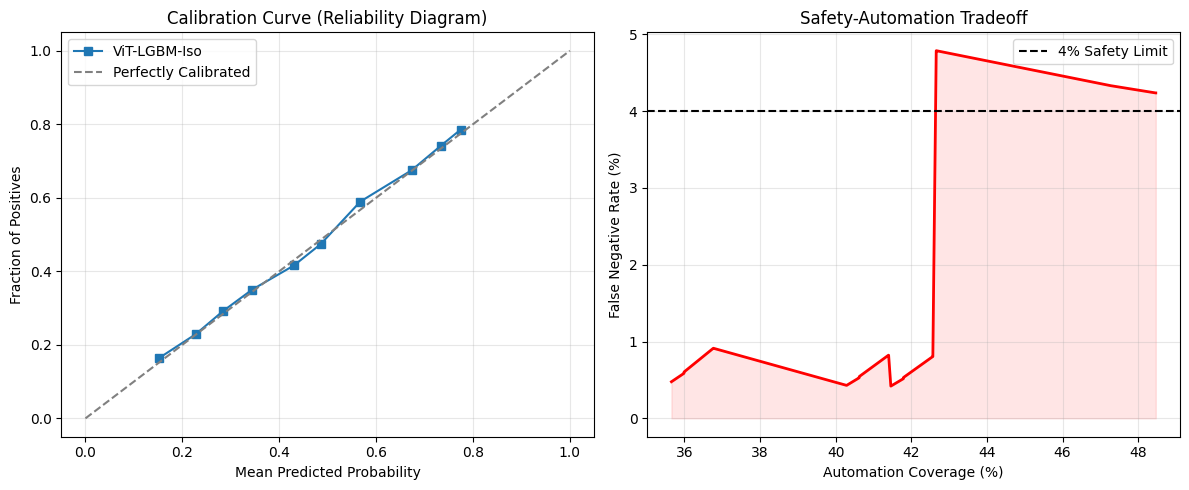

In [10]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

# --- PLOT A: CALIBRATION (Trustworthiness) ---
prob_true, prob_pred = calibration_curve(y_test, test_probs, n_bins=10, strategy='quantile')

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(prob_pred, prob_true, marker='s', label='ViT-LGBM-Iso')
plt.plot([0, 1], [0, 1], '--', color='gray', label='Perfectly Calibrated')
plt.title('Calibration Curve (Reliability Diagram)')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.legend()
plt.grid(alpha=0.3)

# --- PLOT B: COVERAGE VS FN RATE (The Main Paper Figure) ---
# Assuming 'res_df' from previous run is available
sweep_df = pd.read_csv('threshold_sweep_final.csv').sort_values('Cov')

plt.subplot(1, 2, 2)
plt.plot(sweep_df['Cov'] * 100, sweep_df['FN'] * 100, color='red', lw=2)
plt.fill_between(sweep_df['Cov'] * 100, sweep_df['FN'] * 100, color='red', alpha=0.1)
plt.axhline(y=4.0, color='black', linestyle='--', label='4% Safety Limit')
plt.title('Safety-Automation Tradeoff')
plt.xlabel('Automation Coverage (%)')
plt.ylabel('False Negative Rate (%)')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('figure_master_validation.png', dpi=300)
plt.show()